<a href="https://www.kaggle.com/code/lalit7881/fertility-data-eda-90?scriptVersionId=373804318" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muhamedyoussry/fertility-data-set/fertility.csv


## Loading dataset


In [2]:
df = pd.read_csv("/kaggle/input/datasets/muhamedyoussry/fertility-data-set/fertility.csv")

In [3]:
df.head()

,Season,Age,Childish diseases,Accident or serious trauma,Surgical intervention,High fevers in the last year,Frequency of alcohol consumption,Smoking habit,Number of hours spent sitting per day,Diagnosis
0,spring,30,no,yes,yes,more than 3 months ago,once a week,occasional,16,Normal
1,spring,35,yes,no,yes,more than 3 months ago,once a week,daily,6,Altered
2,spring,27,yes,no,no,more than 3 months ago,hardly ever or never,never,9,Normal
3,spring,32,no,yes,yes,more than 3 months ago,hardly ever or never,never,7,Normal
4,spring,30,yes,yes,no,more than 3 months ago,once a week,never,9,Altered


In [4]:
df.tail()

,Season,Age,Childish diseases,Accident or serious trauma,Surgical intervention,High fevers in the last year,Frequency of alcohol consumption,Smoking habit,Number of hours spent sitting per day,Diagnosis
95,winter,30,yes,no,no,more than 3 months ago,hardly ever or never,never,9,Normal
96,winter,29,yes,no,no,more than 3 months ago,once a week,occasional,9,Normal
97,winter,30,yes,yes,yes,more than 3 months ago,hardly ever or never,never,6,Normal
98,winter,30,yes,no,yes,more than 3 months ago,hardly ever or never,occasional,3,Normal
99,winter,30,no,yes,yes,more than 3 months ago,several times a week,never,3,Normal


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   Season                                 100 non-null    object
 1   Age                                    100 non-null    int64 
 2   Childish diseases                      100 non-null    object
 3   Accident or serious trauma             100 non-null    object
 4   Surgical intervention                  100 non-null    object
 5   High fevers in the last year           100 non-null    object
 6   Frequency of alcohol consumption       100 non-null    object
 7   Smoking habit                          100 non-null    object
 8   Number of hours spent sitting per day  100 non-null    int64 
 9   Diagnosis                              100 non-null    object
dtypes: int64(2), object(8)
memory usage: 7.9+ KB


In [6]:
df.describe()

,Age,Number of hours spent sitting per day
count,100.000000,100.000000
mean,30.110000,10.800000
std,2.246861,33.616975
min,27.000000,1.000000
25%,28.000000,5.000000
50%,30.000000,7.000000
75%,32.000000,9.000000
max,36.000000,342.000000


In [7]:
df.isnull().sum()

Season                                   0
Age                                      0
Childish diseases                        0
Accident or serious trauma               0
Surgical intervention                    0
High fevers in the last year             0
Frequency of alcohol consumption         0
Smoking habit                            0
Number of hours spent sitting per day    0
Diagnosis                                0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.dtypes

Season                                   object
Age                                       int64
Childish diseases                        object
Accident or serious trauma               object
Surgical intervention                    object
High fevers in the last year             object
Frequency of alcohol consumption         object
Smoking habit                            object
Number of hours spent sitting per day     int64
Diagnosis                                object
dtype: object

In [10]:
df.shape

(100, 10)

In [11]:
df.columns

Index(['Season', 'Age', 'Childish diseases', 'Accident or serious trauma',
       'Surgical intervention', 'High fevers in the last year',
       'Frequency of alcohol consumption', 'Smoking habit',
       'Number of hours spent sitting per day', 'Diagnosis'],
      dtype='object')

In [12]:
df.nunique()

Season                                    4
Age                                      10
Childish diseases                         2
Accident or serious trauma                2
Surgical intervention                     2
High fevers in the last year              3
Frequency of alcohol consumption          5
Smoking habit                             3
Number of hours spent sitting per day    14
Diagnosis                                 2
dtype: int64

## EDA

DATASET OVERVIEW

First 5 Rows:


,Season,Age,Childish diseases,Accident or serious trauma,Surgical intervention,High fevers in the last year,Frequency of alcohol consumption,Smoking habit,Number of hours spent sitting per day,Diagnosis
0,spring,30,no,yes,yes,more than 3 months ago,once a week,occasional,16,Normal
1,spring,35,yes,no,yes,more than 3 months ago,once a week,daily,6,Altered
2,spring,27,yes,no,no,more than 3 months ago,hardly ever or never,never,9,Normal
3,spring,32,no,yes,yes,more than 3 months ago,hardly ever or never,never,7,Normal
4,spring,30,yes,yes,no,more than 3 months ago,once a week,never,9,Altered



Dataset Shape: (100, 10)

Column Names:
['Season', 'Age', 'Childish diseases', 'Accident or serious trauma', 'Surgical intervention', 'High fevers in the last year', 'Frequency of alcohol consumption', 'Smoking habit', 'Number of hours spent sitting per day', 'Diagnosis']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   Season                                 100 non-null    object
 1   Age                                    100 non-null    int64 
 2   Childish diseases                      100 non-null    object
 3   Accident or serious trauma             100 non-null    object
 4   Surgical intervention                  100 non-null    object
 5   High fevers in the last year           100 non-null    object
 6   Frequency of alcohol consumption       100 non-null    obje

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Season,100,4,spring,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,100.0,NaN,NaN,NaN,30.11,2.246861,27.0,28.0,30.0,32.0,36.0
Childish diseases,100,2,yes,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Accident or serious trauma,100,2,no,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Surgical intervention,100,2,yes,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
High fevers in the last year,100,3,more than 3 months ago,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency of alcohol consumption,100,5,hardly ever or never,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoking habit,100,3,never,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number of hours spent sitting per day,100.0,NaN,NaN,NaN,10.8,33.616975,1.0,5.0,7.0,9.0,342.0
Diagnosis,100,2,Normal,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
Season                                   0
Age                                      0
Childish diseases                        0
Accident or serious trauma               0
Surgical intervention                    0
High fevers in the last year             0
Frequency of alcohol consumption         0
Smoking habit                            0
Number of hours spent sitting per day    0
Diagnosis                                0
dtype: int64

Duplicate Records: 1

Numerical Columns: ['Age', 'Number of hours spent sitting per day']

Categorical Columns: ['Season', 'Childish diseases', 'Accident or serious trauma', 'Surgical intervention', 'High fevers in the last year', 'Frequency of alcohol consumption', 'Smoking habit', 'Diagnosis']


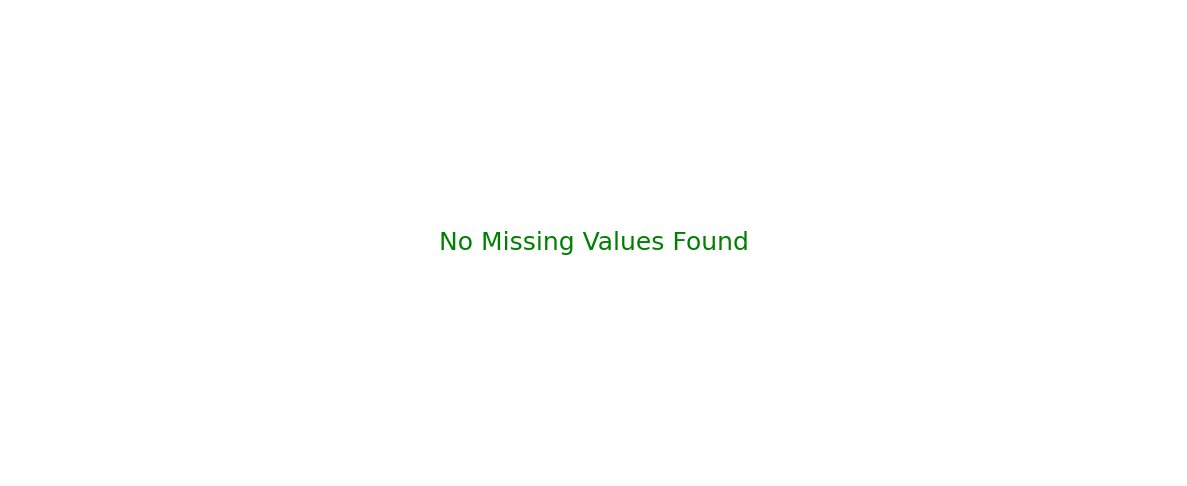

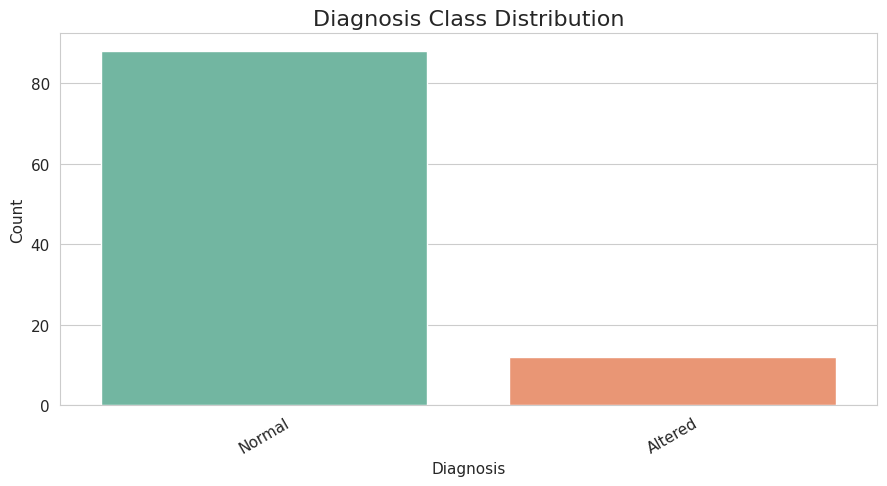


Diagnosis Percentage:


,Percentage
Diagnosis,
Normal,88.0
Altered,12.0


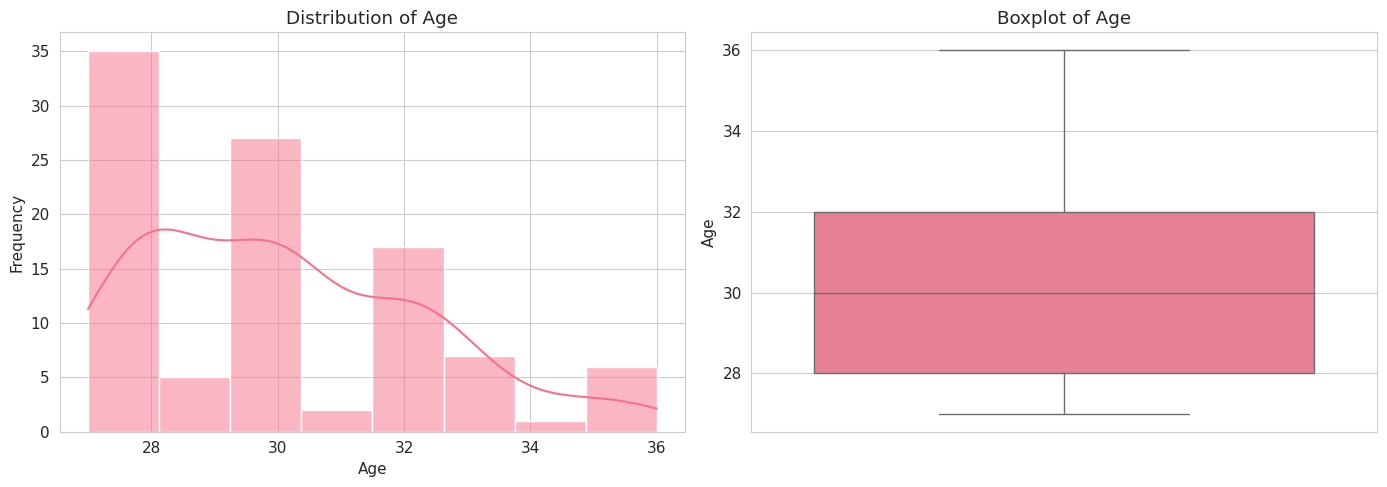

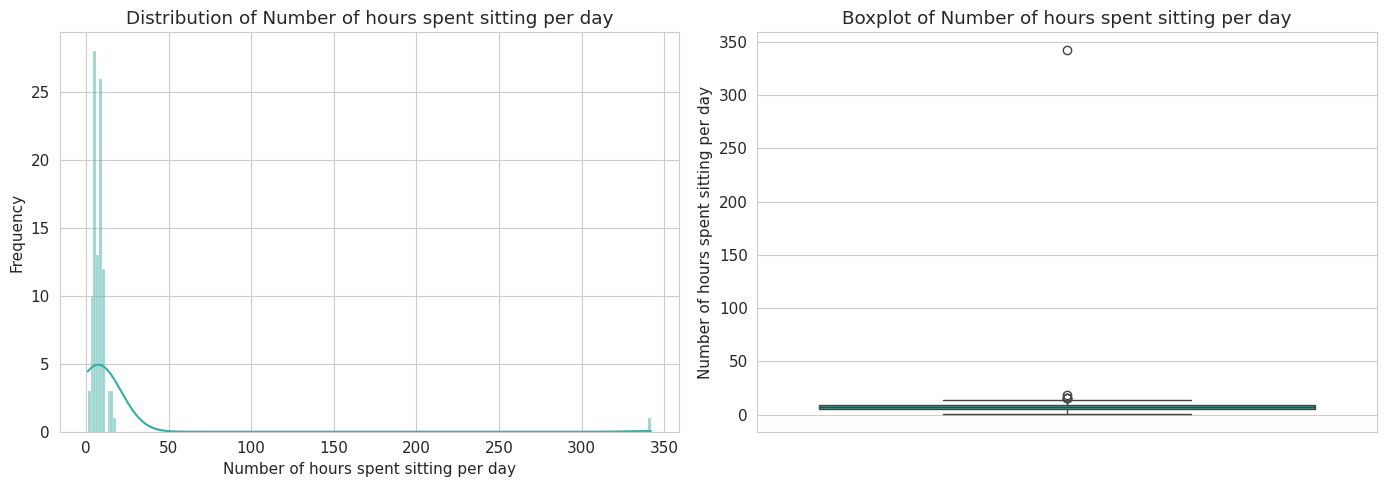

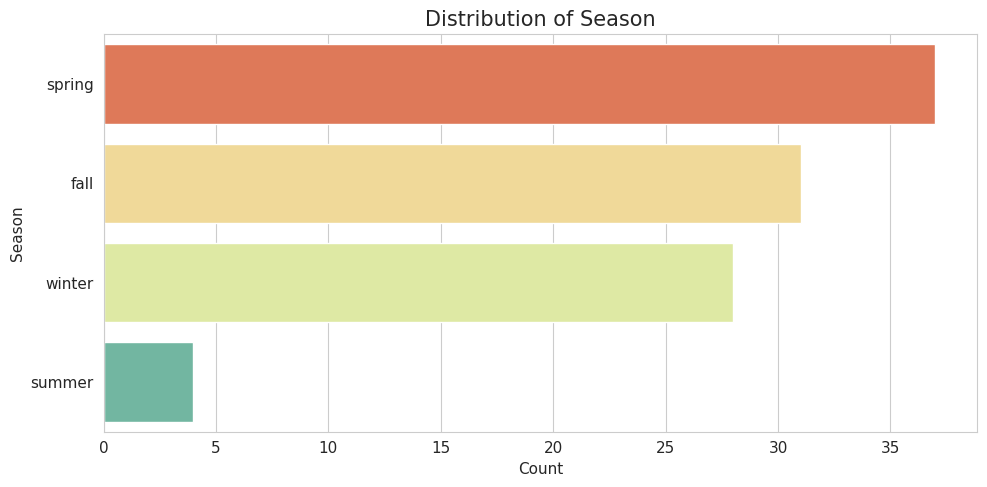

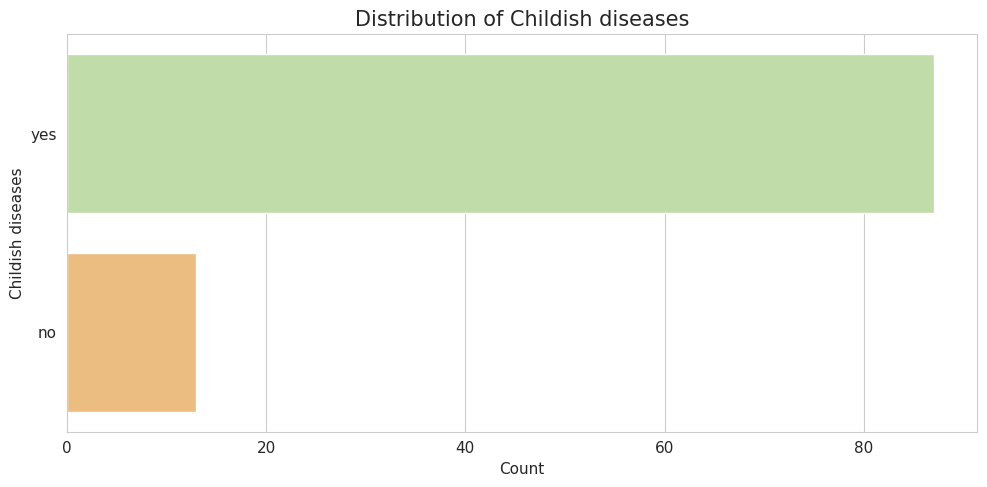

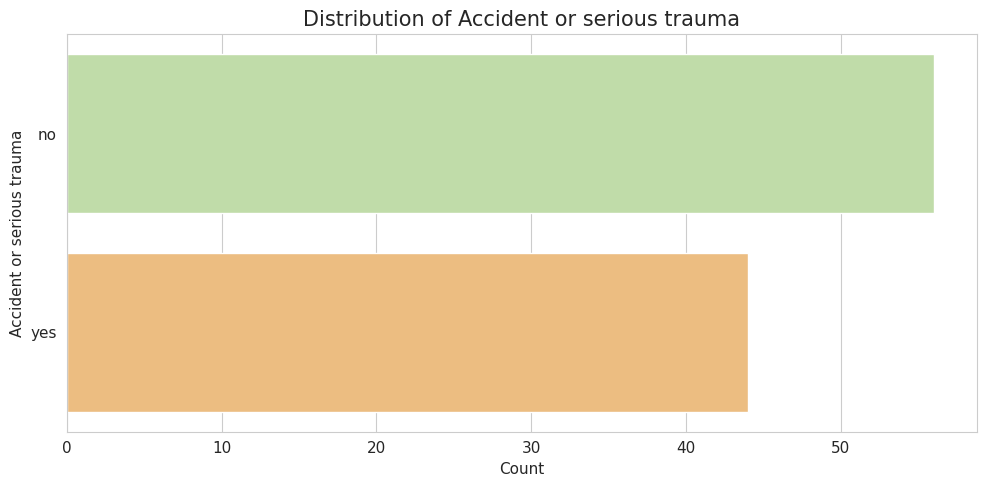

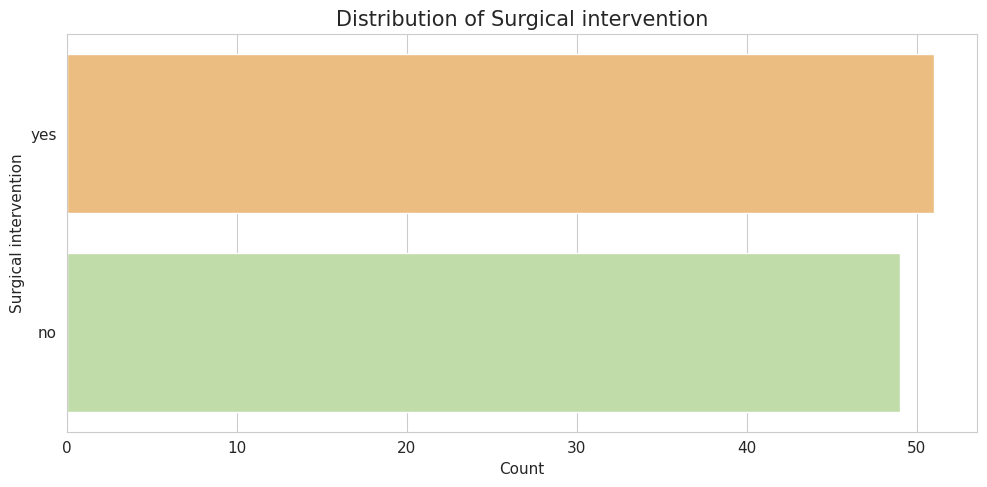

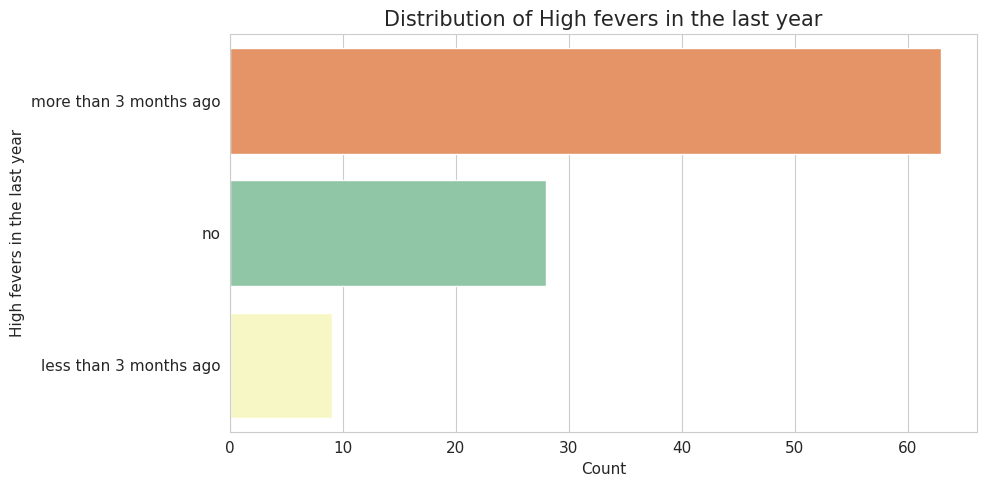

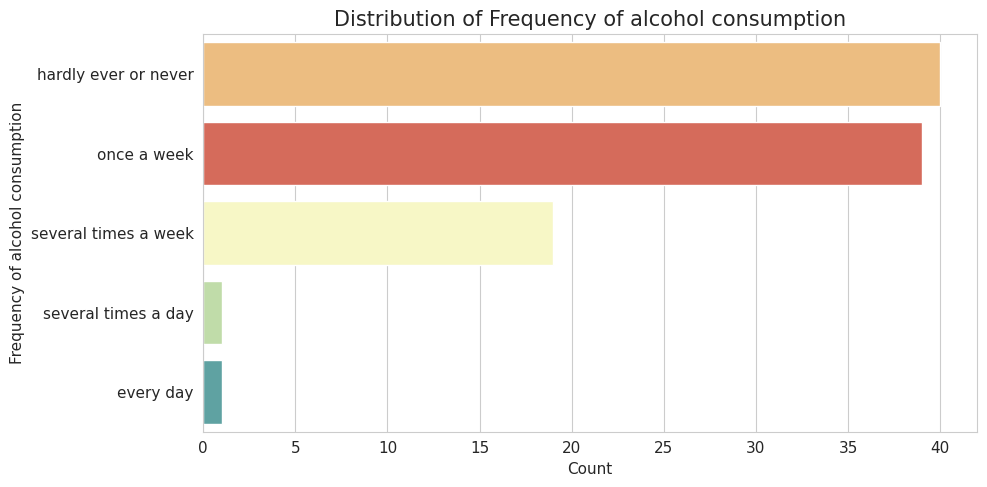

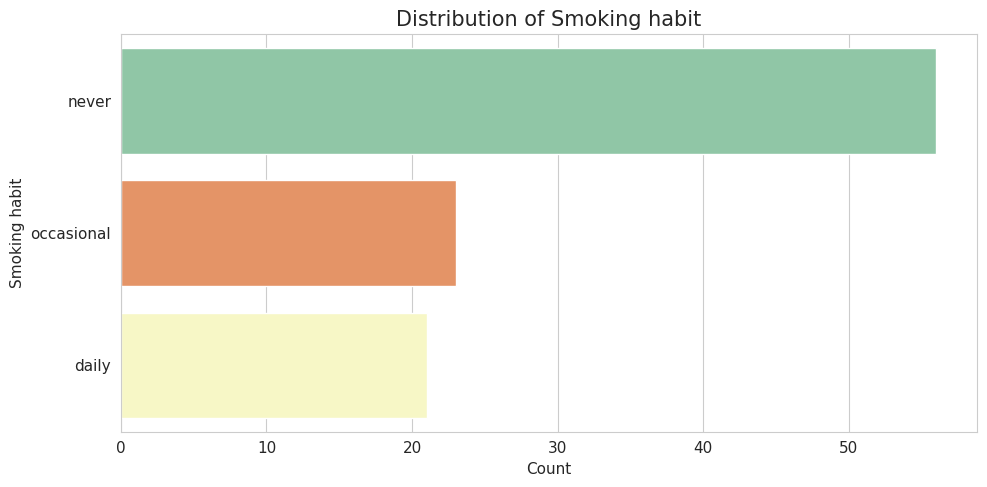

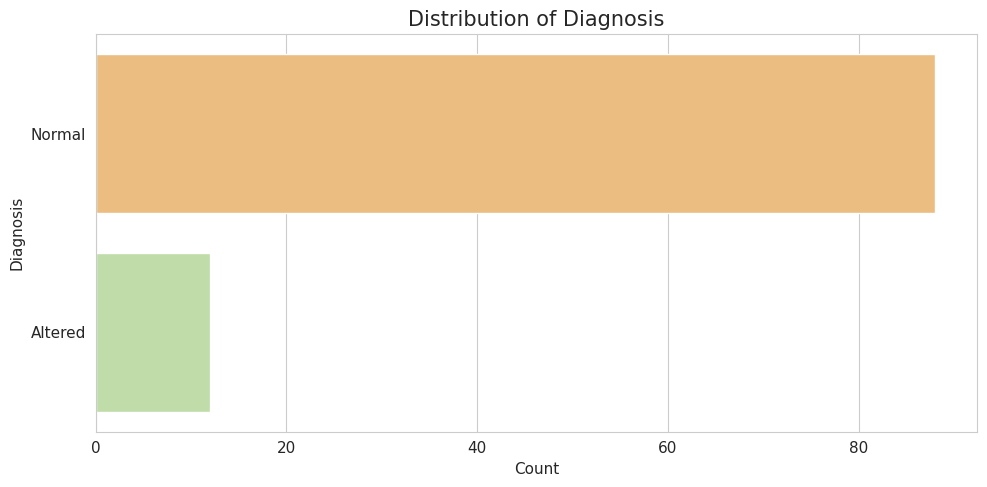

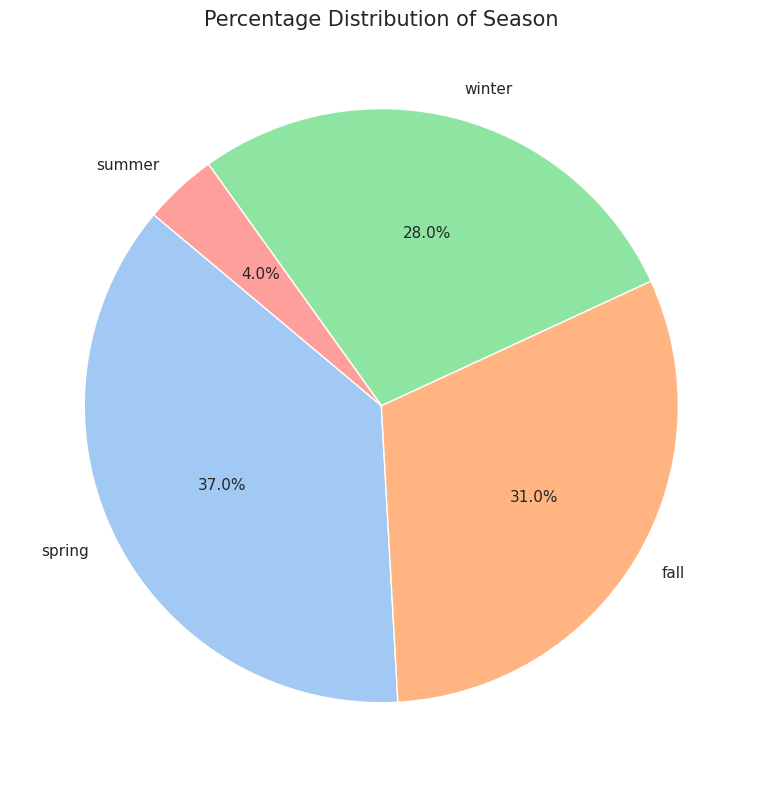

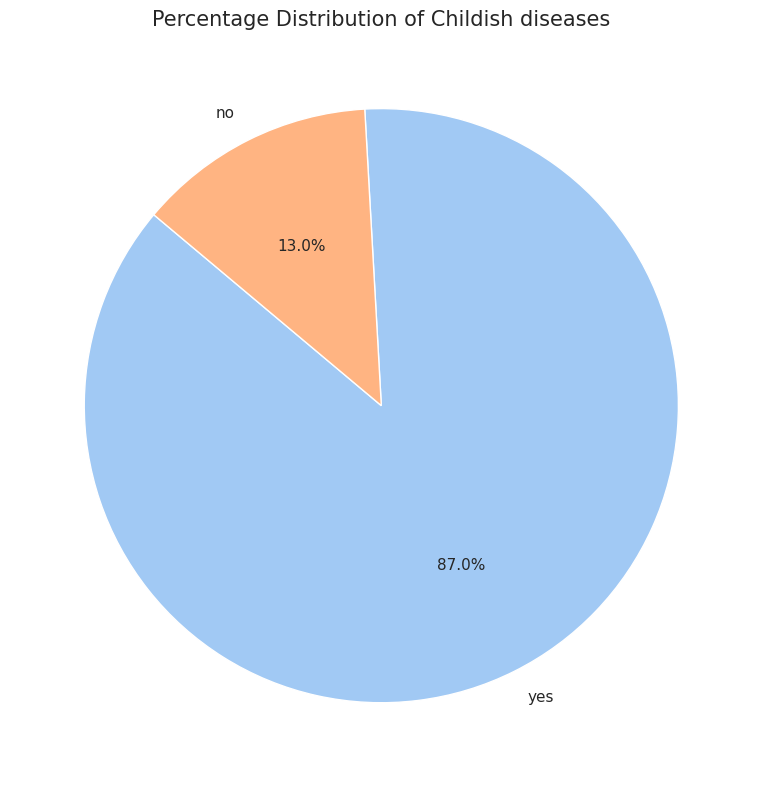

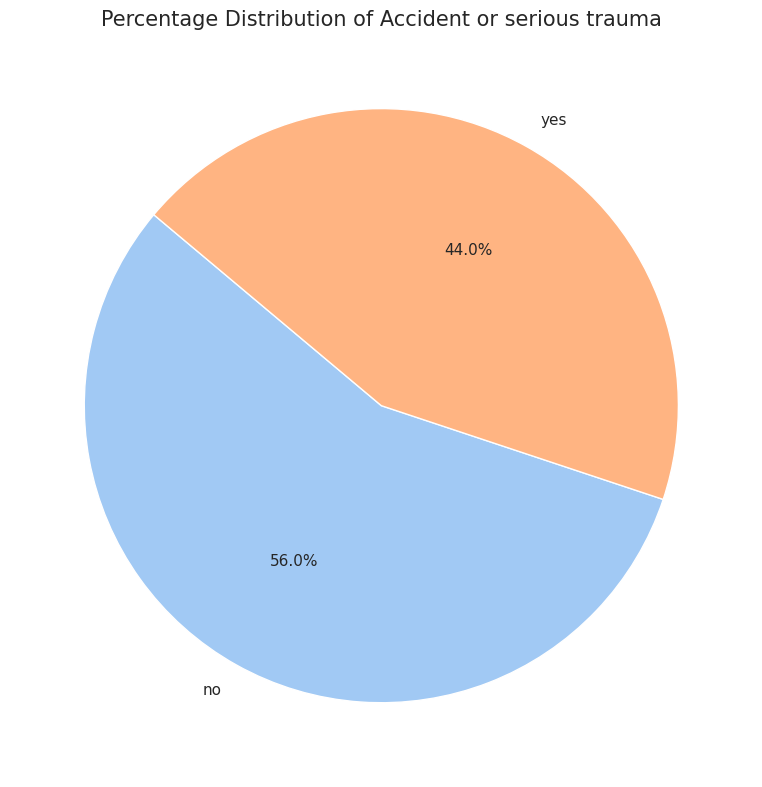

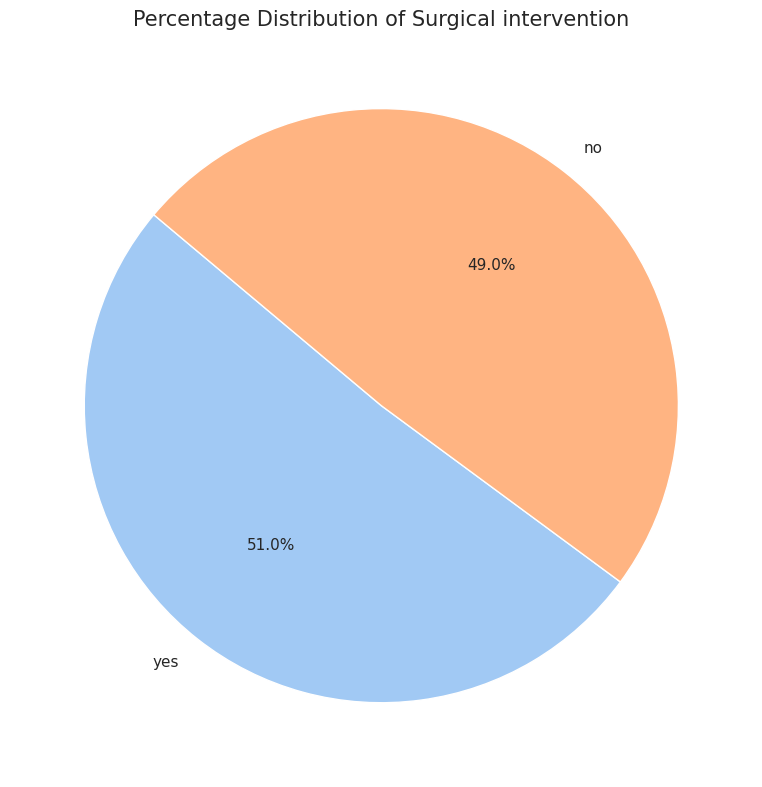

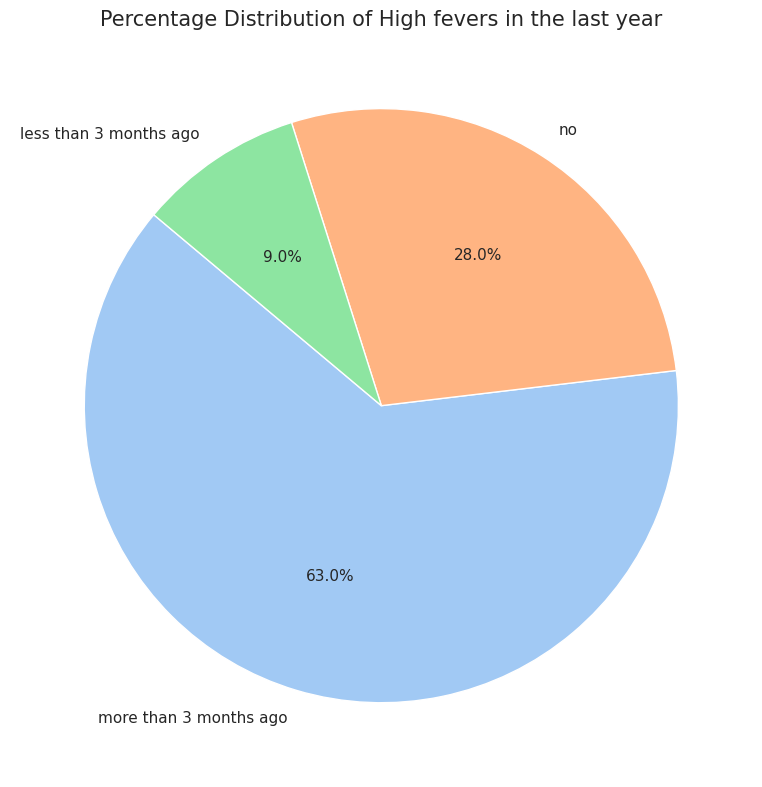

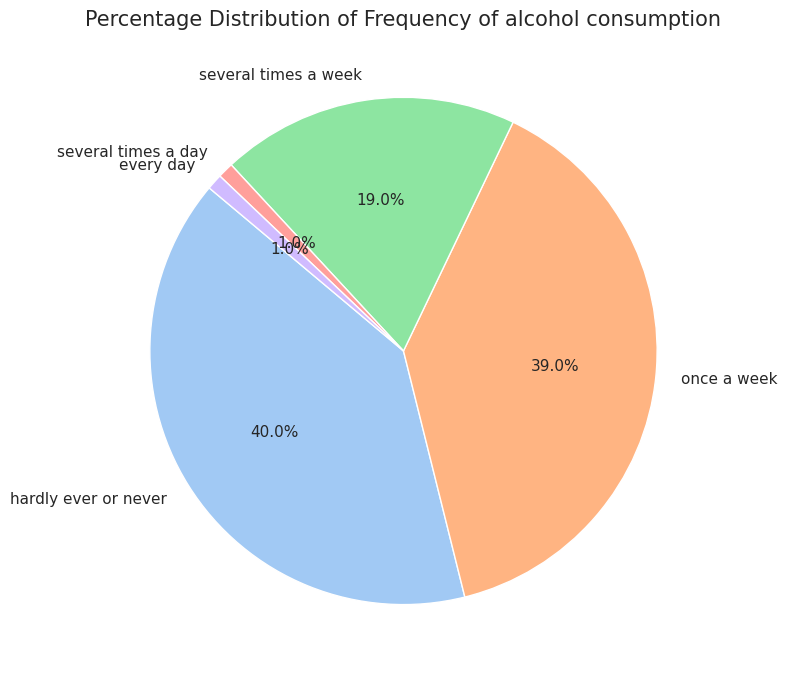

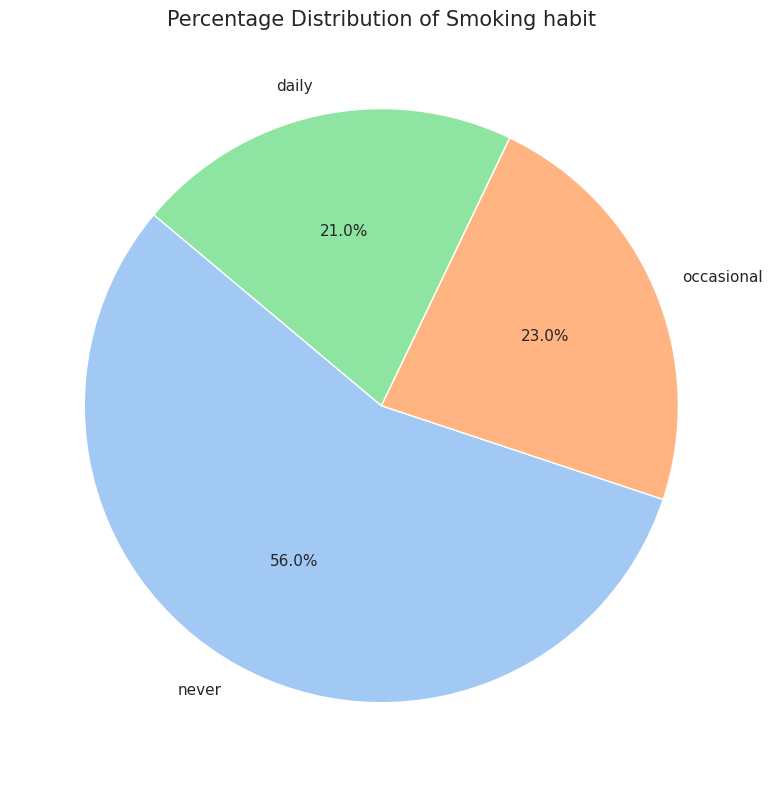

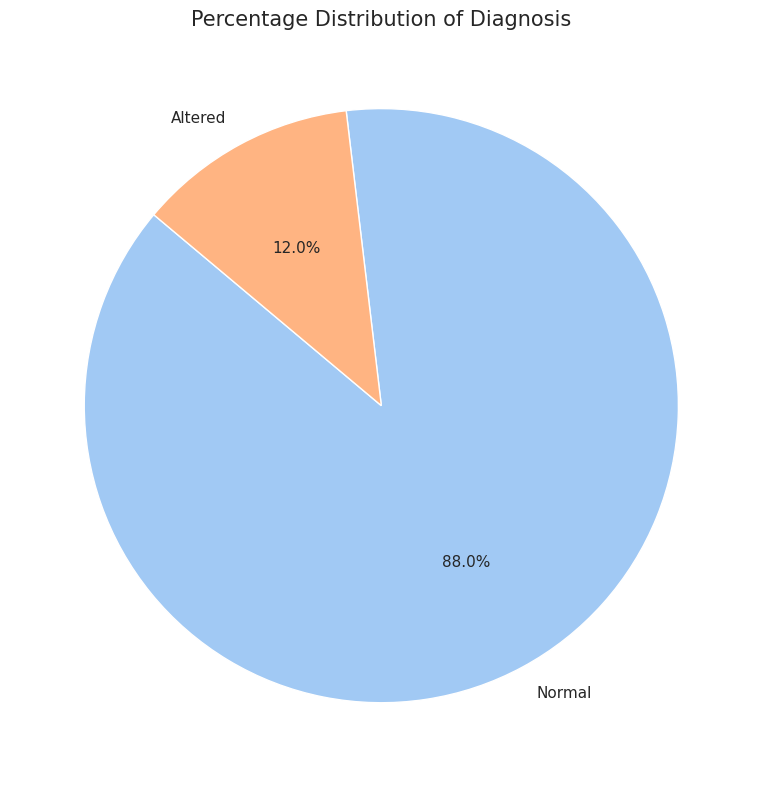

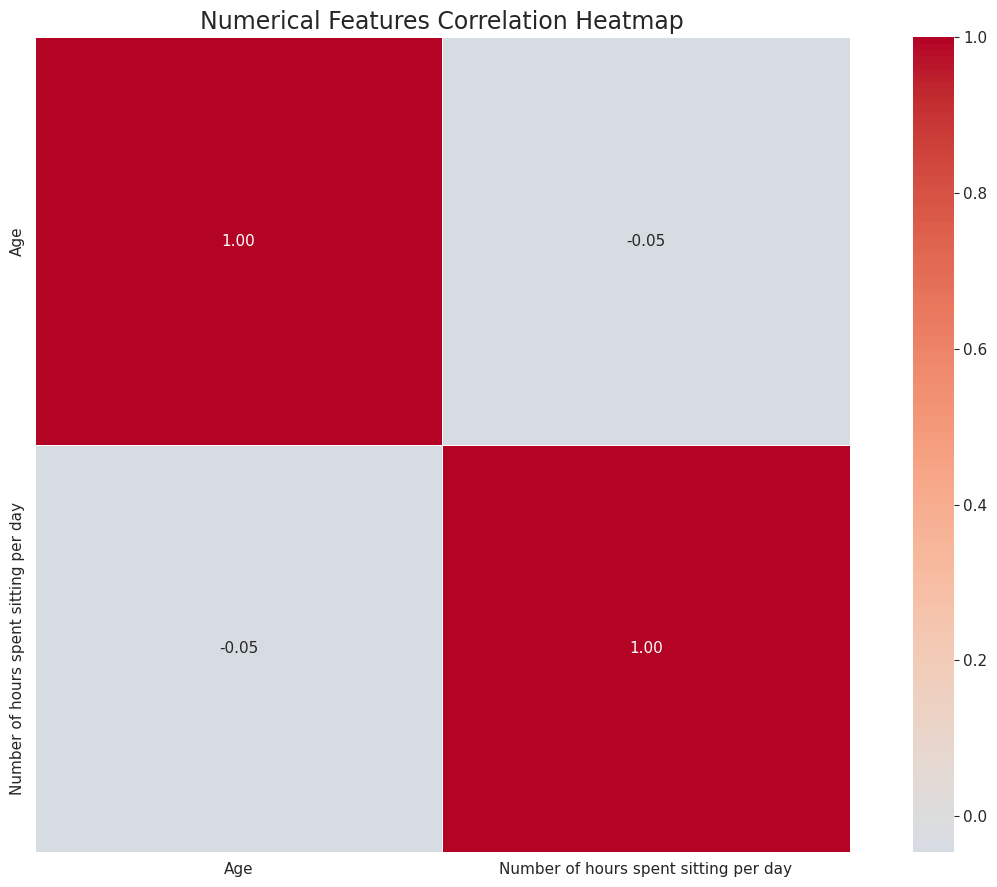

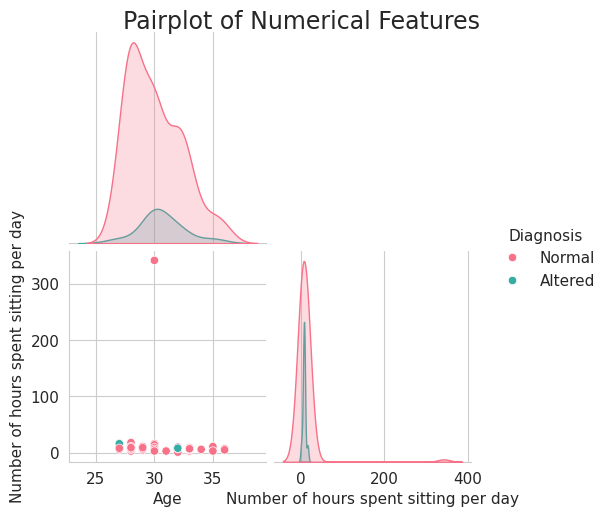

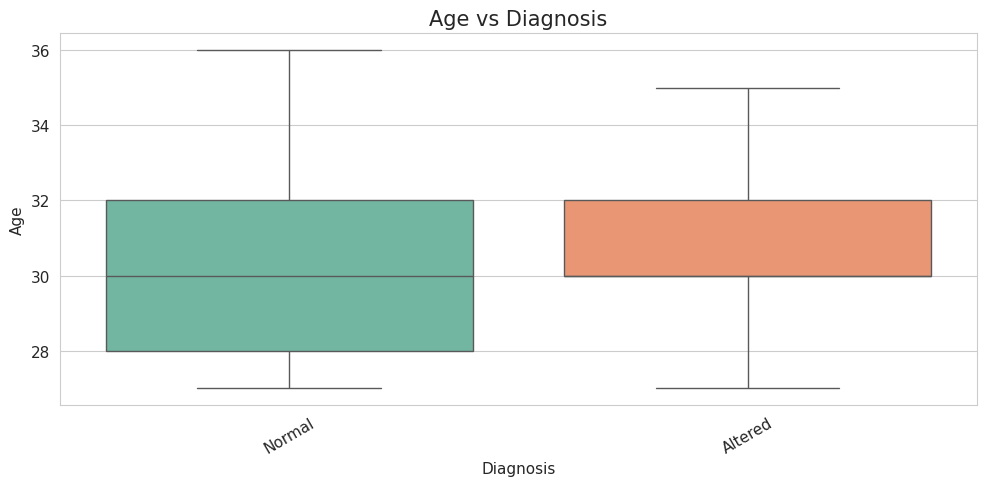

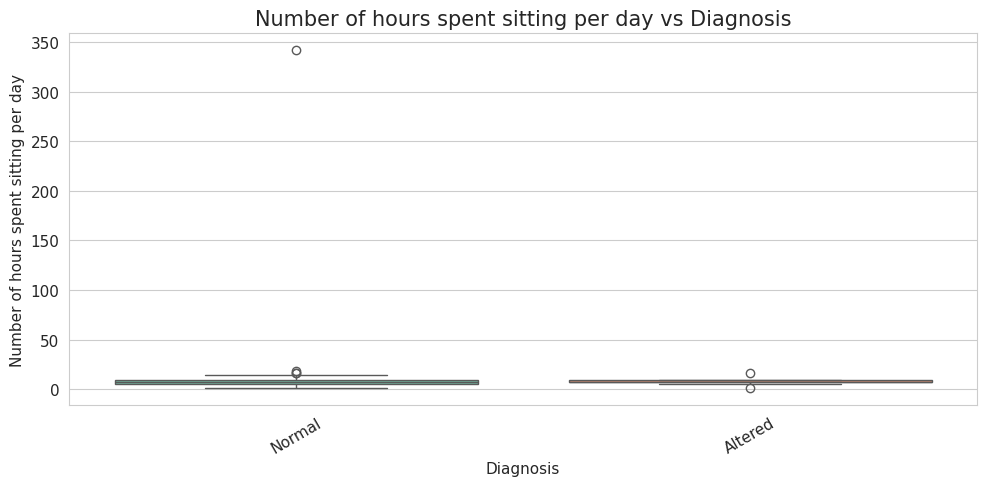

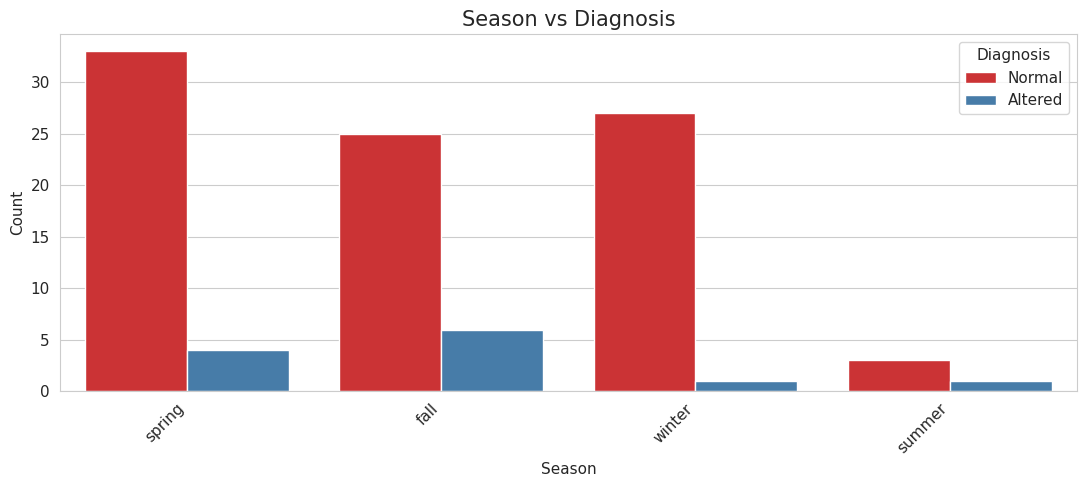

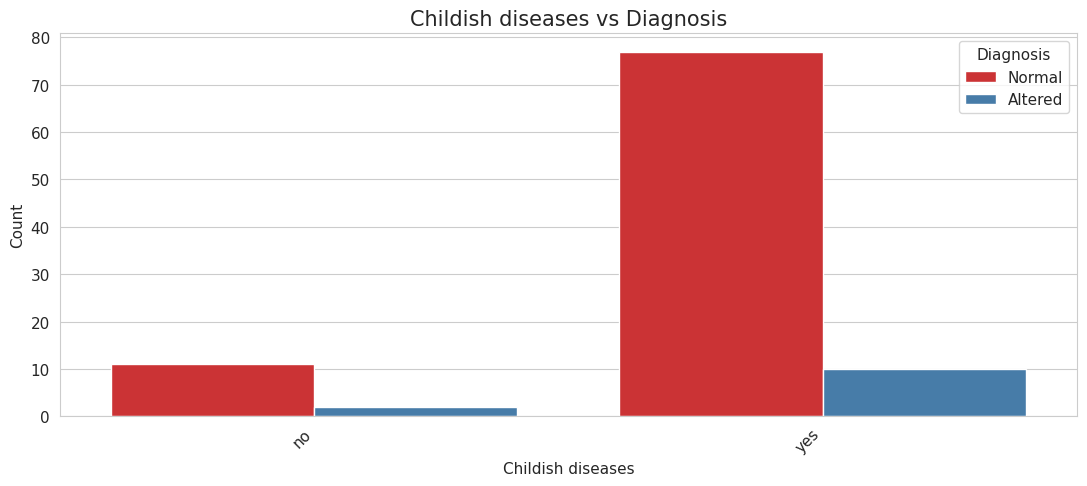

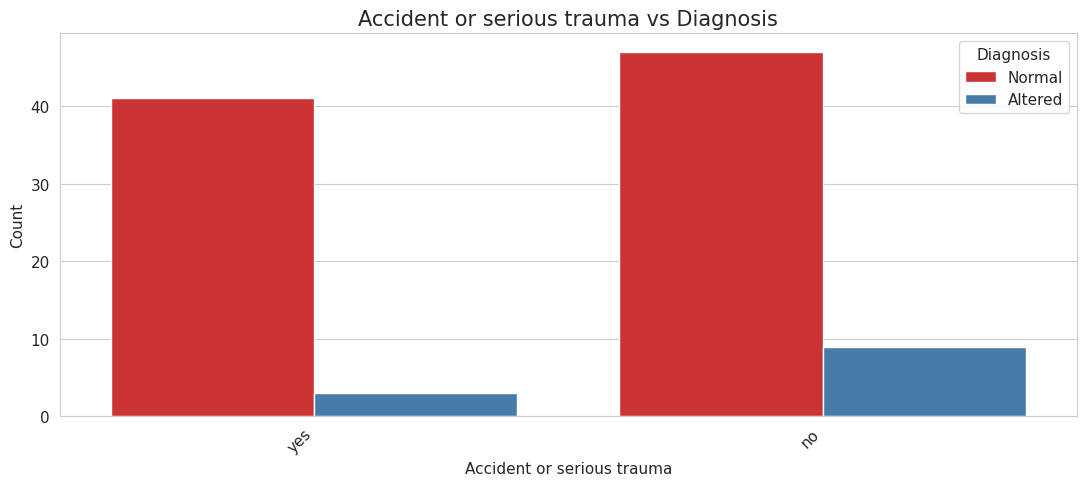

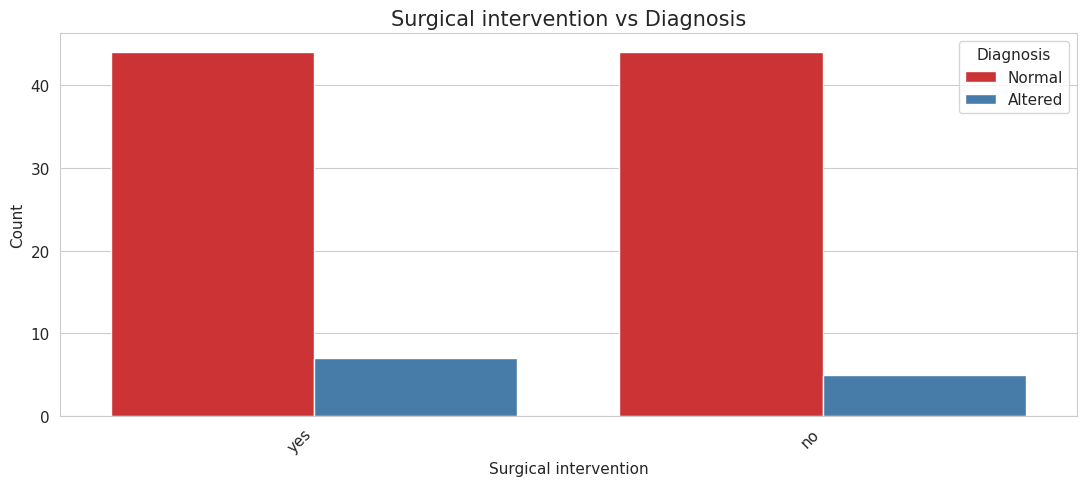

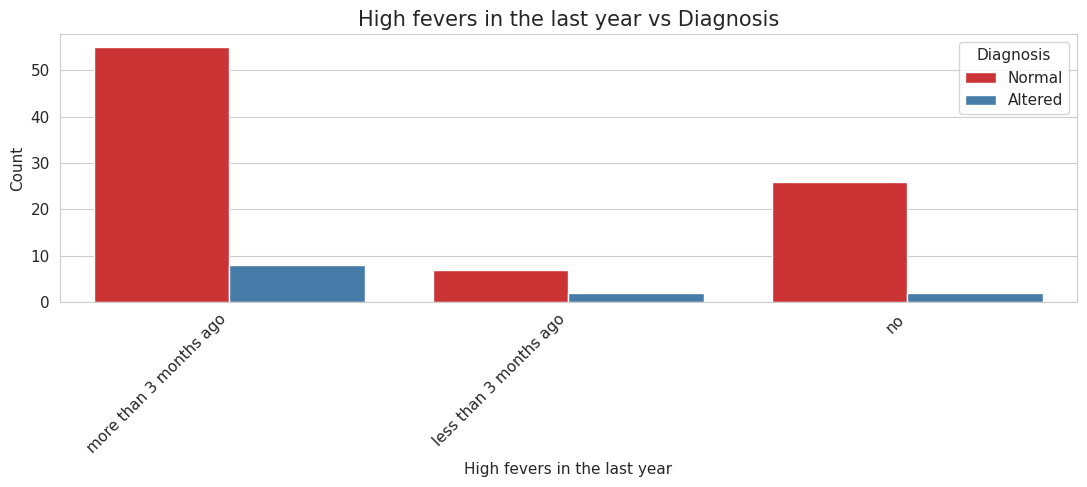

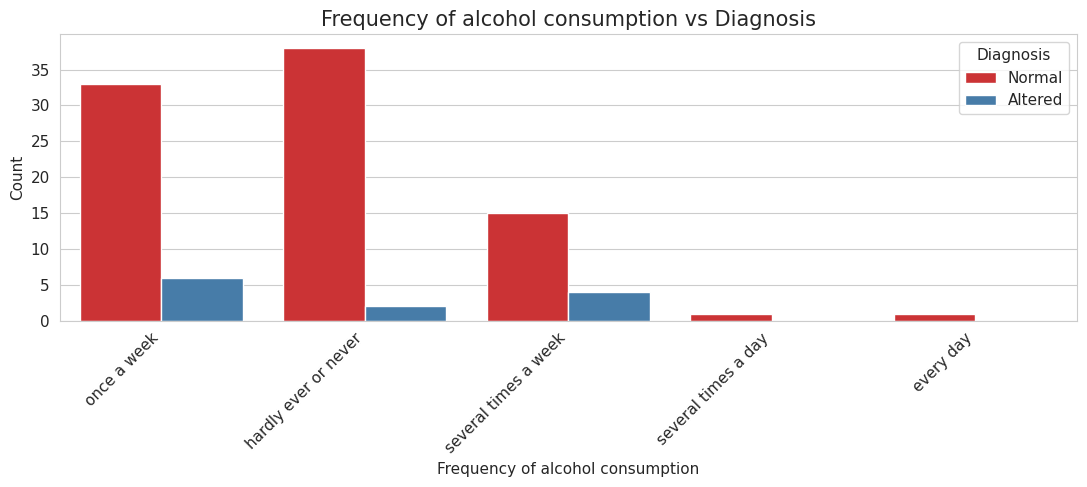

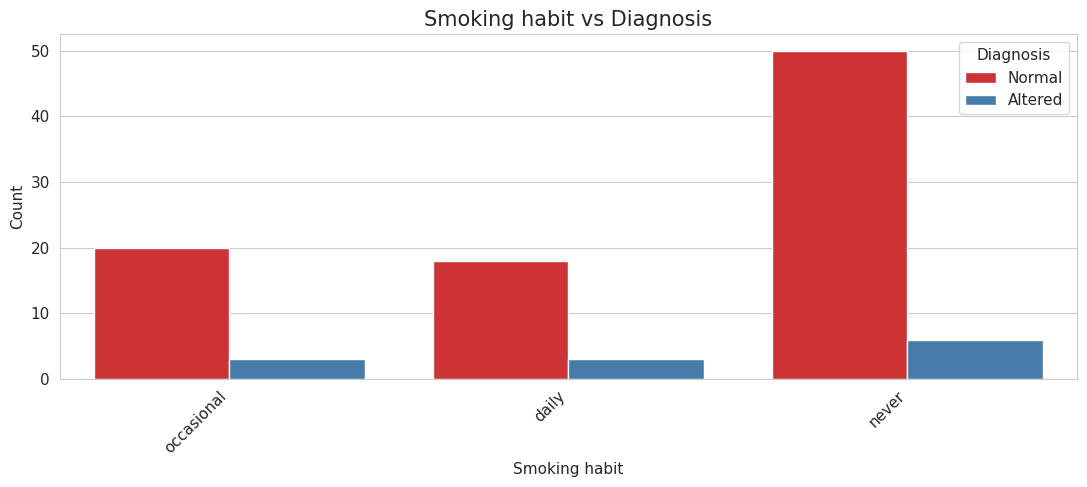

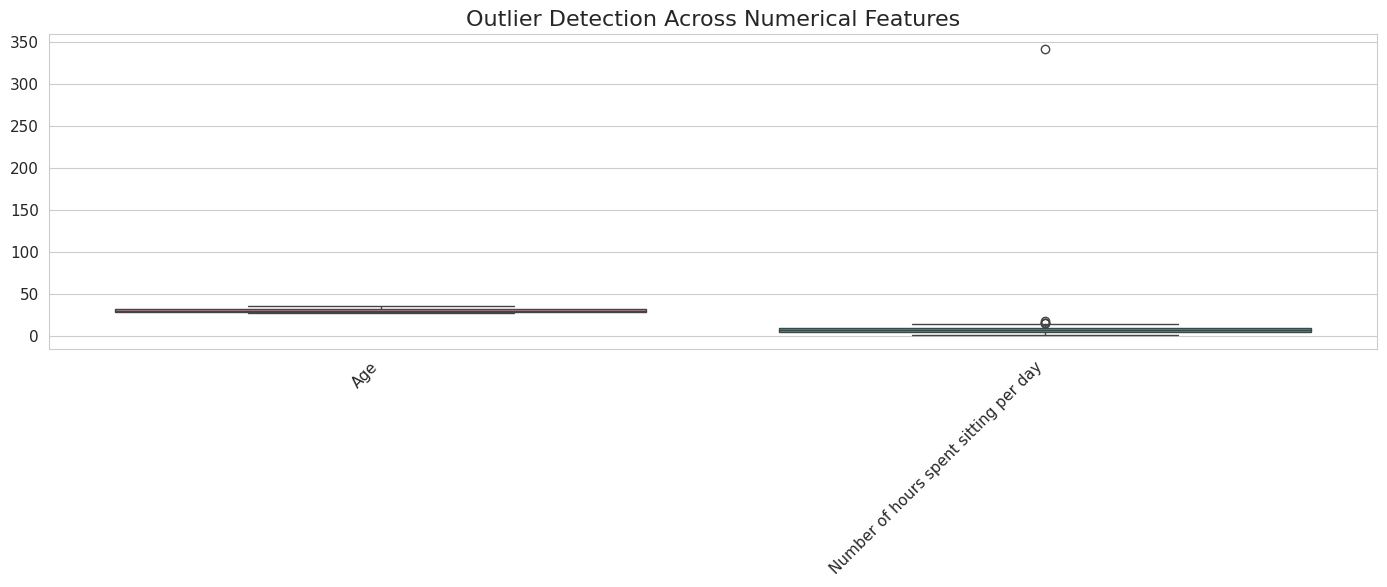


OUTLIER COUNT USING IQR METHOD
Age: 0 outliers
Number of hours spent sitting per day: 5 outliers


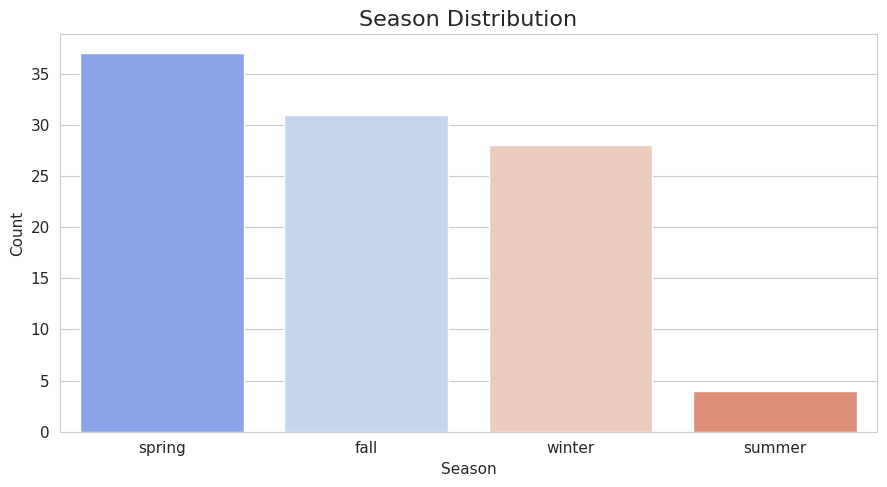

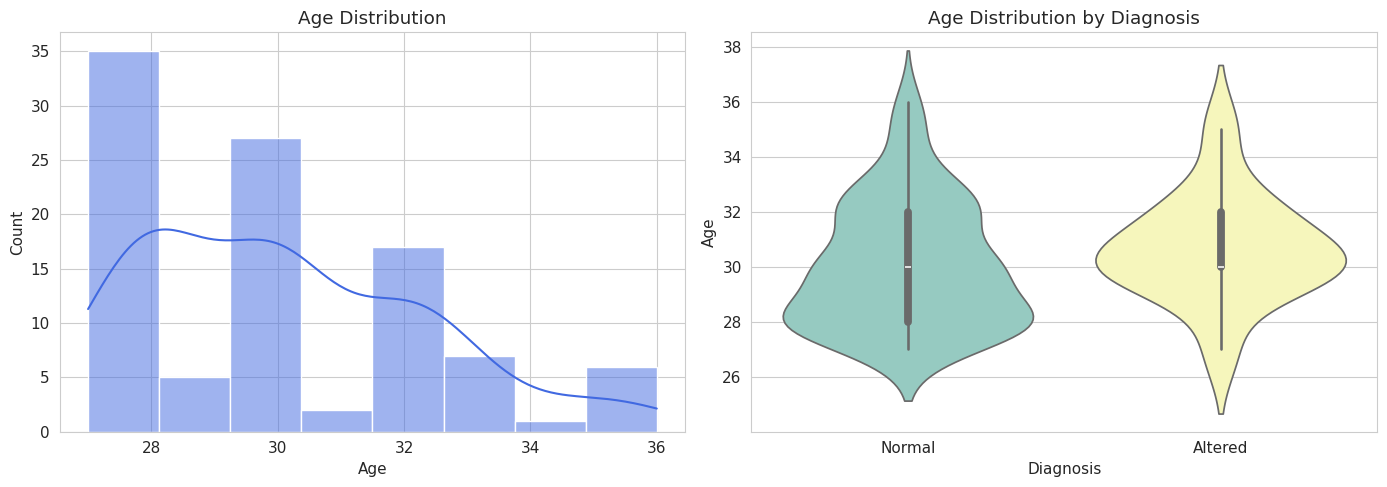

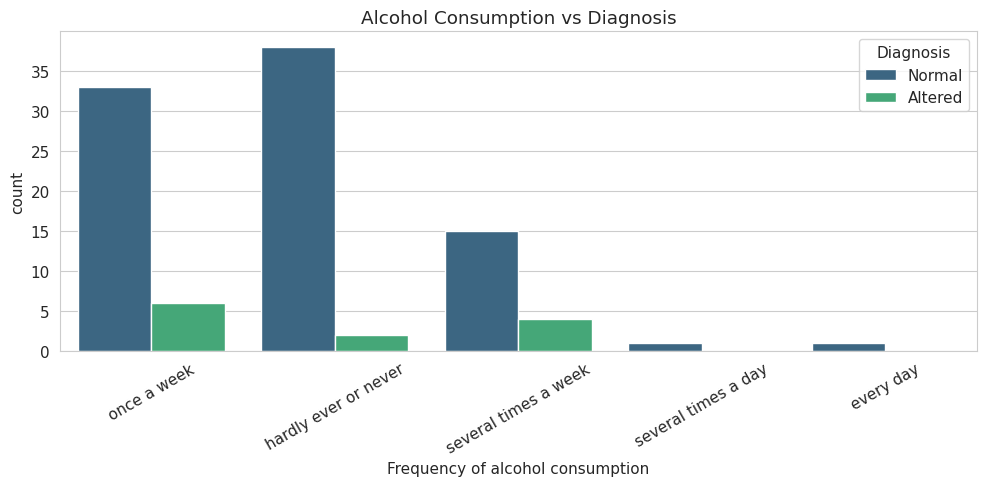

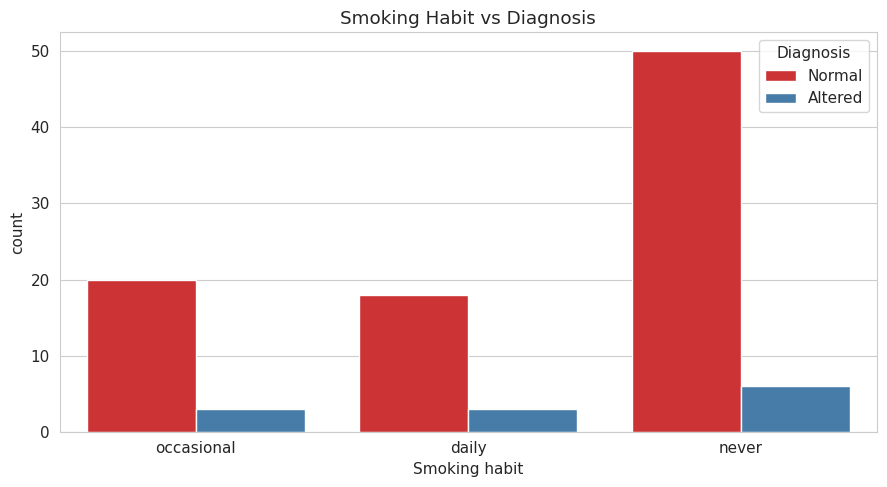

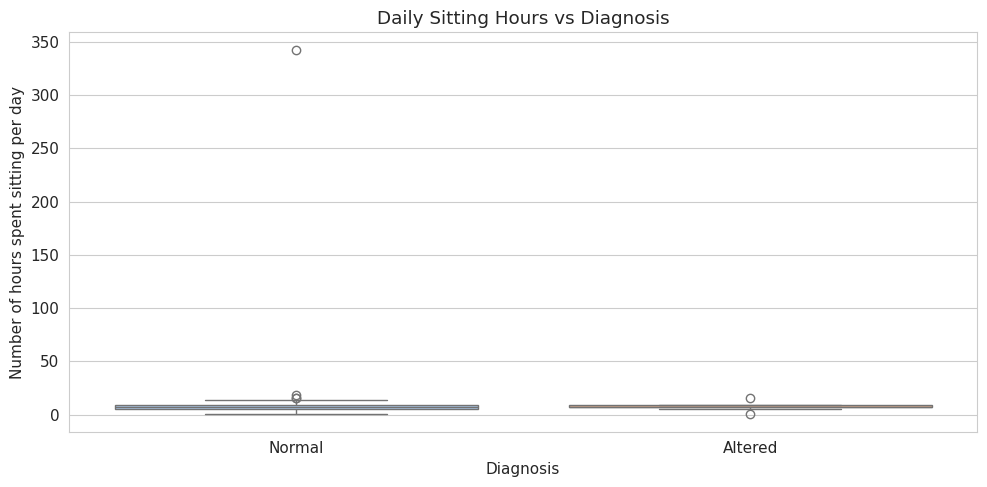


Mean Numerical Features by Diagnosis:


,Age,Number of hours spent sitting per day
Diagnosis,,
Altered,30.666667,7.666667
Normal,30.034091,11.227273


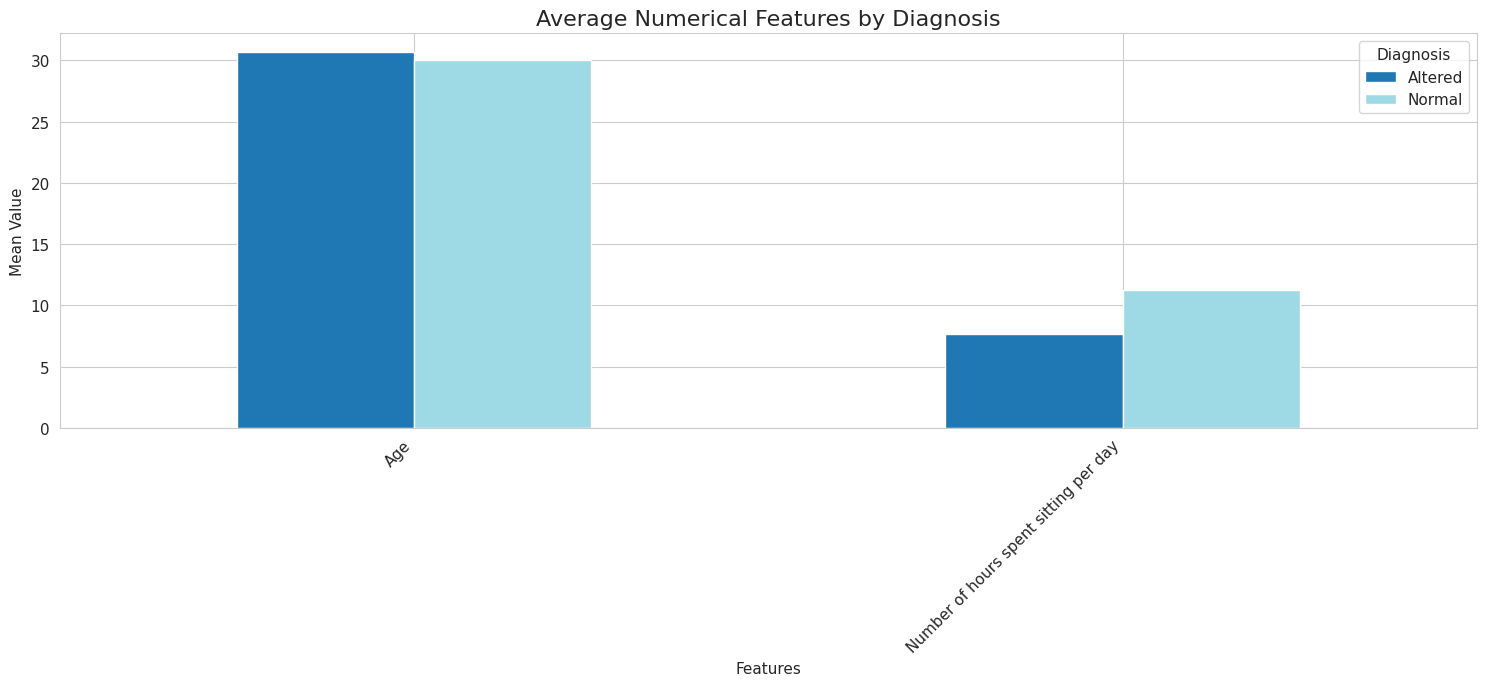


FINAL EDA SUMMARY
Total Rows: 100
Total Columns: 10
Numerical Features: 2
Categorical Features: 8
Missing Values: 0
Duplicate Rows: 1

Diagnosis Distribution:
Diagnosis
Normal     88
Altered    12
Name: count, dtype: int64

EDA VISUALIZATION COMPLETED SUCCESSFULLY!


In [13]:

# ============================================================
# COMPLETE EDA & DATA VISUALIZATION
# ============================================================
# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# ============================================================
# 2. DATA OVERVIEW
# ============================================================

print("=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all').T)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# ============================================================
# 3. SEPARATE NUMERICAL AND CATEGORICAL COLUMNS
# ============================================================

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nNumerical Columns:", numerical_cols)
print("\nCategorical Columns:", categorical_cols)

# ============================================================
# 4. MISSING VALUES VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 5))

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    sns.barplot(
        x=missing.values,
        y=missing.index,
        hue=missing.index,
        palette='magma',
        legend=False
    )
    plt.title("Missing Values Distribution", fontsize=16)
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Columns")
else:
    plt.text(0.5, 0.5, "No Missing Values Found",
             ha='center', va='center', fontsize=18,
             color='green')
    plt.axis('off')

plt.tight_layout()
plt.show()

# ============================================================
# 5. TARGET VARIABLE: DIAGNOSIS
# ============================================================

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Diagnosis',
    hue='Diagnosis',
    palette='Set2',
    legend=False
)

plt.title("Diagnosis Class Distribution", fontsize=16)
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Target percentage
print("\nDiagnosis Percentage:")
display(
    (df['Diagnosis'].value_counts(normalize=True) * 100)
    .round(2).to_frame("Percentage")
)

# ============================================================
# 6. NUMERICAL FEATURES DISTRIBUTION
# ============================================================

if numerical_cols:

    colors = sns.color_palette("husl", len(numerical_cols))

    for i, col in enumerate(numerical_cols):

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # Histogram
        sns.histplot(
            data=df,
            x=col,
            kde=True,
            color=colors[i],
            ax=axes[0]
        )

        axes[0].set_title(f"Distribution of {col}")
        axes[0].set_xlabel(col)
        axes[0].set_ylabel("Frequency")

        # Boxplot
        sns.boxplot(
            data=df,
            y=col,
            color=colors[i],
            ax=axes[1]
        )

        axes[1].set_title(f"Boxplot of {col}")

        plt.tight_layout()
        plt.show()

# ============================================================
# 7. CATEGORICAL FEATURES DISTRIBUTION
# ============================================================

for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        hue=col,
        palette='Spectral',
        legend=False
    )

    plt.title(f"Distribution of {col}", fontsize=15)
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

# ============================================================
# 8. PIE CHARTS FOR CATEGORICAL FEATURES
# ============================================================

for col in categorical_cols:

    counts = df[col].value_counts()

    plt.figure(figsize=(8, 8))

    plt.pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct='%1.1f%%',
        startangle=140,
        colors=sns.color_palette('pastel', len(counts)),
        wedgeprops={'edgecolor': 'white', 'linewidth': 1}
    )

    plt.title(f"Percentage Distribution of {col}", fontsize=15)
    plt.tight_layout()
    plt.show()

# ============================================================
# 9. CORRELATION HEATMAP
# ============================================================

if len(numerical_cols) > 1:

    plt.figure(figsize=(13, 9))

    correlation = df[numerical_cols].corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap='coolwarm',
        fmt='.2f',
        linewidths=0.5,
        square=True,
        center=0
    )

    plt.title("Numerical Features Correlation Heatmap", fontsize=17)
    plt.tight_layout()
    plt.show()

# ============================================================
# 10. PAIRPLOT
# ============================================================

if len(numerical_cols) >= 2:

    pair_cols = numerical_cols[:6]

    pair_data = df[pair_cols].copy()

    if 'Diagnosis' in df.columns:
        pair_data['Diagnosis'] = df['Diagnosis'].astype(str)

    sns.pairplot(
        pair_data,
        hue='Diagnosis' if 'Diagnosis' in pair_data.columns else None,
        palette='husl',
        diag_kind='kde',
        corner=True
    )

    plt.suptitle("Pairplot of Numerical Features",
                 y=1.02, fontsize=17)
    plt.show()

# ============================================================
# 11. FEATURE DISTRIBUTION BY DIAGNOSIS
# ============================================================

for col in numerical_cols:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x='Diagnosis',
        y=col,
        hue='Diagnosis',
        palette='Set2',
        legend=False
    )

    plt.title(f"{col} vs Diagnosis", fontsize=15)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ============================================================
# 12. CATEGORICAL FEATURES VS DIAGNOSIS
# ============================================================

for col in categorical_cols:

    if col != 'Diagnosis':

        plt.figure(figsize=(11, 5))

        sns.countplot(
            data=df,
            x=col,
            hue='Diagnosis',
            palette='Set1'
        )

        plt.title(f"{col} vs Diagnosis", fontsize=15)
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha='right')
        plt.legend(title='Diagnosis')
        plt.tight_layout()
        plt.show()

# ============================================================
# 13. OUTLIER DETECTION
# ============================================================

if numerical_cols:

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        data=df[numerical_cols],
        palette='husl'
    )

    plt.title("Outlier Detection Across Numerical Features",
              fontsize=16)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # IQR Method
    print("\nOUTLIER COUNT USING IQR METHOD")

    for col in numerical_cols:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = df[
            (df[col] < lower) | (df[col] > upper)
        ]

        print(f"{col}: {len(outliers)} outliers")

# ============================================================
# 14. SEASON FEATURE ANALYSIS
# ============================================================

if 'Season' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x='Season',
        hue='Season',
        palette='coolwarm',
        legend=False
    )

    plt.title("Season Distribution", fontsize=16)
    plt.xlabel("Season")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# ============================================================
# 15. AGE DISTRIBUTION
# ============================================================

if 'Age' in df.columns:

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.histplot(
        data=df,
        x='Age',
        kde=True,
        color='royalblue',
        ax=axes[0]
    )

    axes[0].set_title("Age Distribution")

    sns.violinplot(
        data=df,
        x='Diagnosis',
        y='Age',
        hue='Diagnosis',
        palette='Set3',
        legend=False,
        ax=axes[1]
    )

    axes[1].set_title("Age Distribution by Diagnosis")

    plt.tight_layout()
    plt.show()

# ============================================================
# 16. ALCOHOL CONSUMPTION VS DIAGNOSIS
# ============================================================

if 'Frequency of alcohol consumption' in df.columns:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x='Frequency of alcohol consumption',
        hue='Diagnosis',
        palette='viridis'
    )

    plt.title("Alcohol Consumption vs Diagnosis")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ============================================================
# 17. SMOKING HABIT VS DIAGNOSIS
# ============================================================

if 'Smoking habit' in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x='Smoking habit',
        hue='Diagnosis',
        palette='Set1'
    )

    plt.title("Smoking Habit vs Diagnosis")
    plt.tight_layout()
    plt.show()

# ============================================================
# 18. SITTING HOURS VS DIAGNOSIS
# ============================================================

if 'Number of hours spent sitting per day' in df.columns:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x='Diagnosis',
        y='Number of hours spent sitting per day',
        hue='Diagnosis',
        palette='pastel',
        legend=False
    )

    plt.title("Daily Sitting Hours vs Diagnosis")
    plt.tight_layout()
    plt.show()

# ============================================================
# 19. FEATURE-WISE MEAN ANALYSIS
# ============================================================

if numerical_cols:

    mean_data = df.groupby('Diagnosis')[numerical_cols].mean()

    print("\nMean Numerical Features by Diagnosis:")
    display(mean_data)

    mean_data.T.plot(
        kind='bar',
        figsize=(15, 7),
        colormap='tab20'
    )

    plt.title("Average Numerical Features by Diagnosis",
              fontsize=16)
    plt.xlabel("Features")
    plt.ylabel("Mean Value")
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Diagnosis')
    plt.tight_layout()
    plt.show()

# ============================================================
# 20. FINAL DATASET SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL EDA SUMMARY")
print("=" * 70)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Numerical Features:", len(numerical_cols))
print("Categorical Features:", len(categorical_cols))
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nDiagnosis Distribution:")
print(df['Diagnosis'].value_counts())

print("\nEDA VISUALIZATION COMPLETED SUCCESSFULLY!")


## Feature engineering

DATASET INFORMATION
Shape: (100, 10)

Columns:
['Season', 'Age', 'Childish diseases', 'Accident or serious trauma', 'Surgical intervention', 'High fevers in the last year', 'Frequency of alcohol consumption', 'Smoking habit', 'Number of hours spent sitting per day', 'Diagnosis']

First 5 Rows:


,Season,Age,Childish diseases,Accident or serious trauma,Surgical intervention,High fevers in the last year,Frequency of alcohol consumption,Smoking habit,Number of hours spent sitting per day,Diagnosis
0,spring,30,no,yes,yes,more than 3 months ago,once a week,occasional,16,Normal
1,spring,35,yes,no,yes,more than 3 months ago,once a week,daily,6,Altered
2,spring,27,yes,no,no,more than 3 months ago,hardly ever or never,never,9,Normal
3,spring,32,no,yes,yes,more than 3 months ago,hardly ever or never,never,7,Normal
4,spring,30,yes,yes,no,more than 3 months ago,once a week,never,9,Altered



Missing Values:
Season                                   0
Age                                      0
Childish diseases                        0
Accident or serious trauma               0
Surgical intervention                    0
High fevers in the last year             0
Frequency of alcohol consumption         0
Smoking habit                            0
Number of hours spent sitting per day    0
Diagnosis                                0
dtype: int64

Target Distribution:
Diagnosis
Normal     88
Altered    12
Name: count, dtype: int64

Categorical Features:
['Season', 'Childish diseases', 'Accident or serious trauma', 'Surgical intervention', 'High fevers in the last year', 'Frequency of alcohol consumption', 'Smoking habit']

Numerical Features:
['Age', 'Number of hours spent sitting per day']

TRAIN TEST SPLIT
X_train: (79, 9)
X_test : (20, 9)
y_train: (79,)
y_test : (20,)

Target Classes:
['Altered' 'Normal']

Encoded Training Target:
[0 1]

Label Encoding Completed!

Feature S

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Decision Tree,90.0,81.000,90.0,85.263,0.389
1,Random Forest,90.0,81.000,90.0,85.263,0.528
2,Extra Trees,90.0,81.000,90.0,85.263,0.778
3,KNN,90.0,81.000,90.0,85.263,0.333
4,SVM,90.0,81.000,90.0,85.263,0.750
5,Gradient Boosting,90.0,81.000,90.0,85.263,0.722
6,LightGBM,90.0,81.000,90.0,85.263,0.722
7,XGBoost,90.0,81.000,90.0,85.263,0.944
8,Logistic Regression,85.0,80.526,85.0,82.703,0.472
9,AdaBoost,85.0,80.526,85.0,82.703,0.722


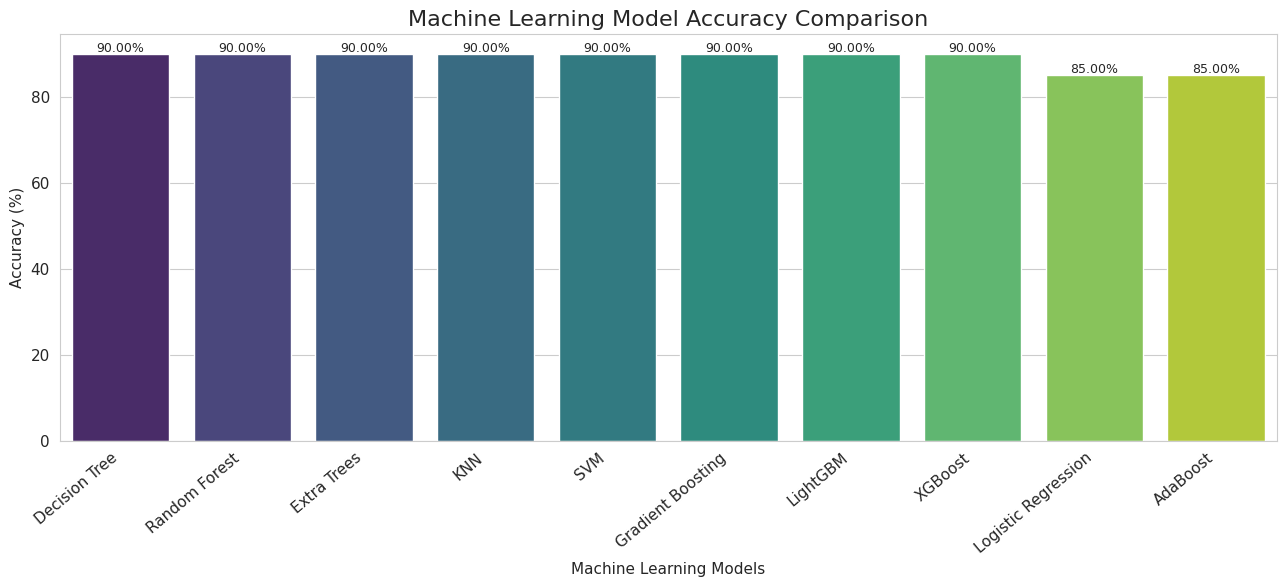

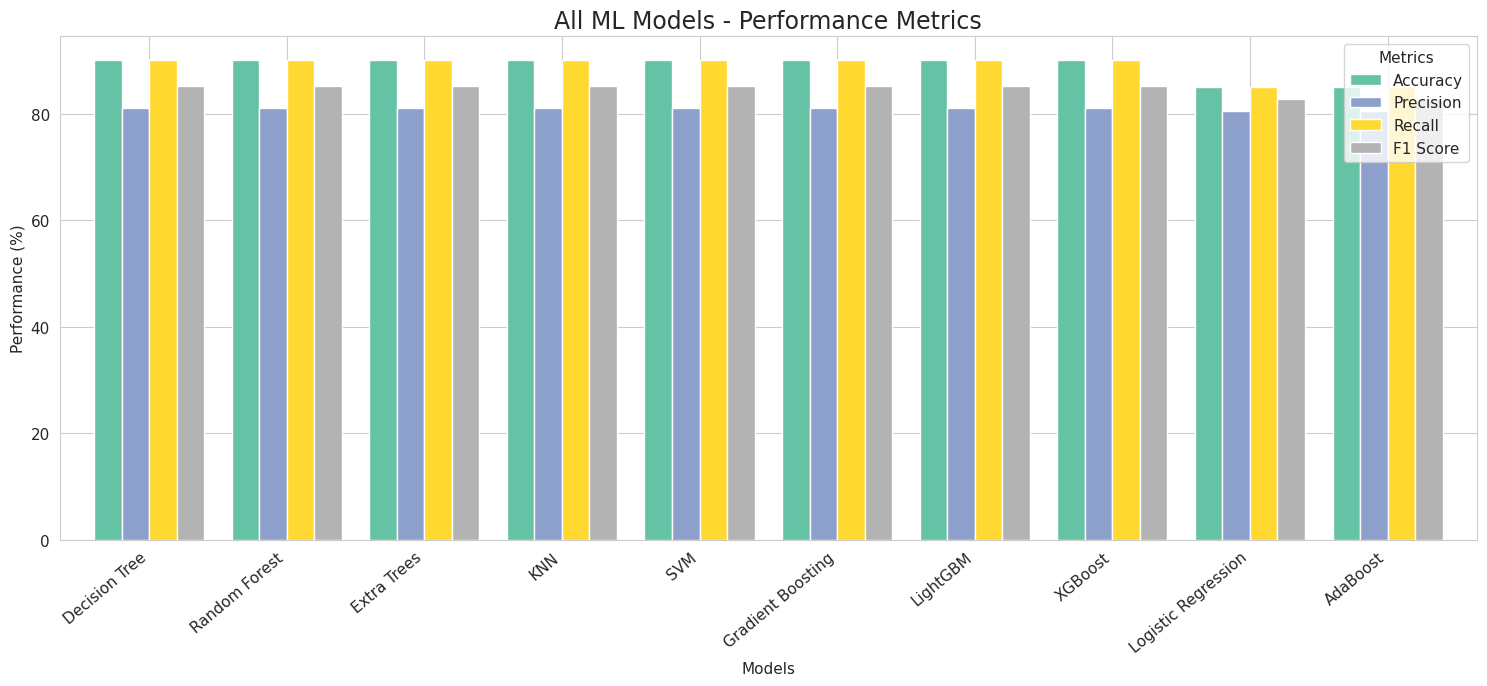

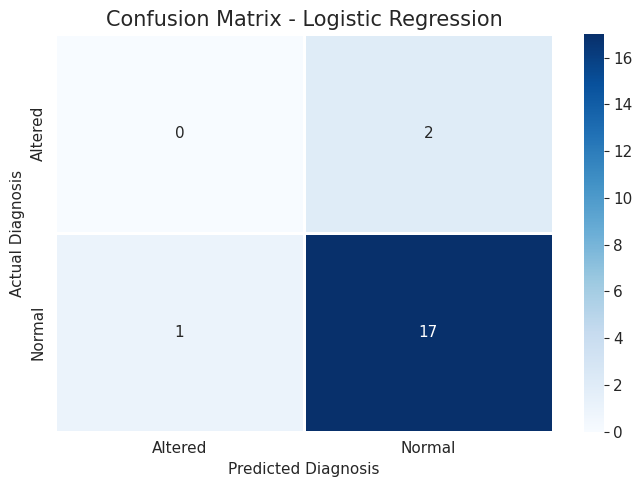

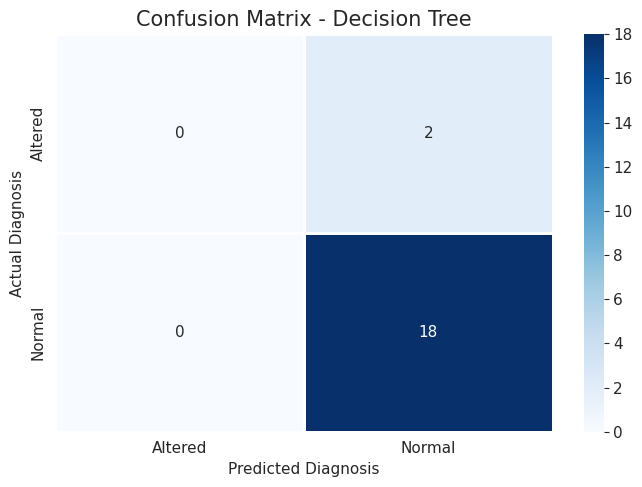

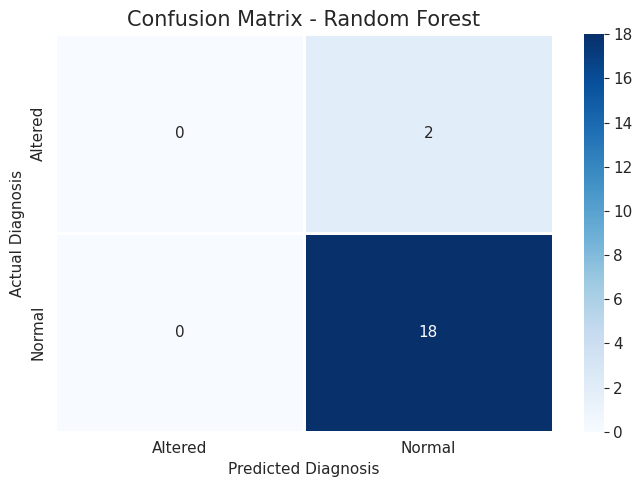

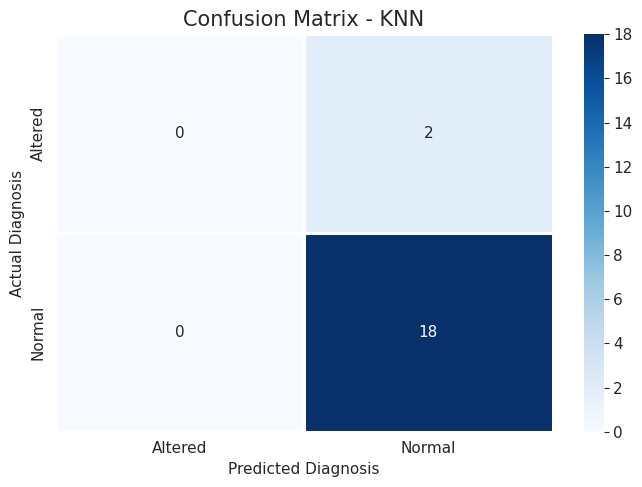

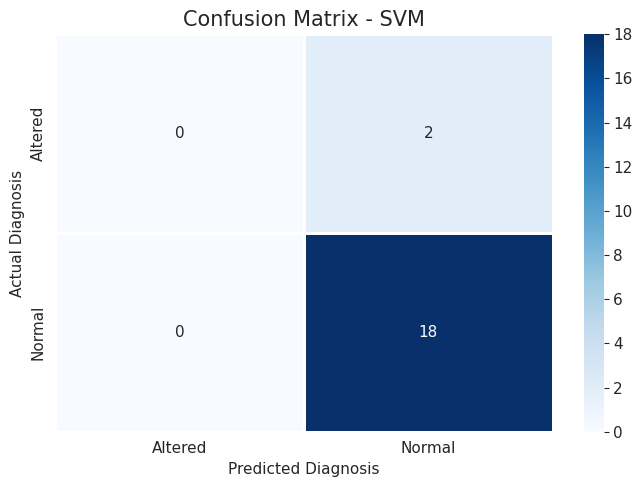

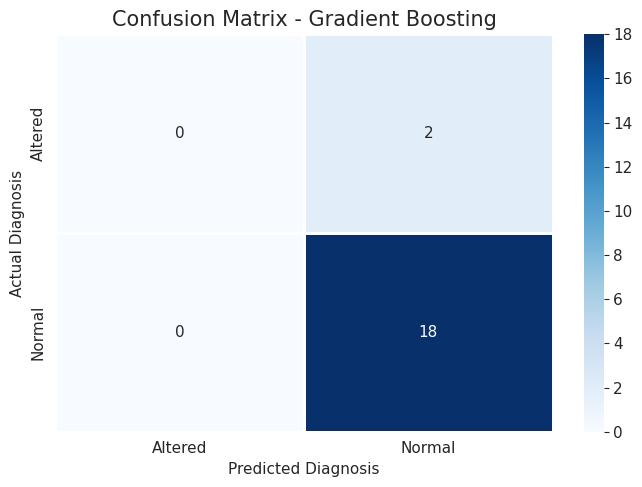

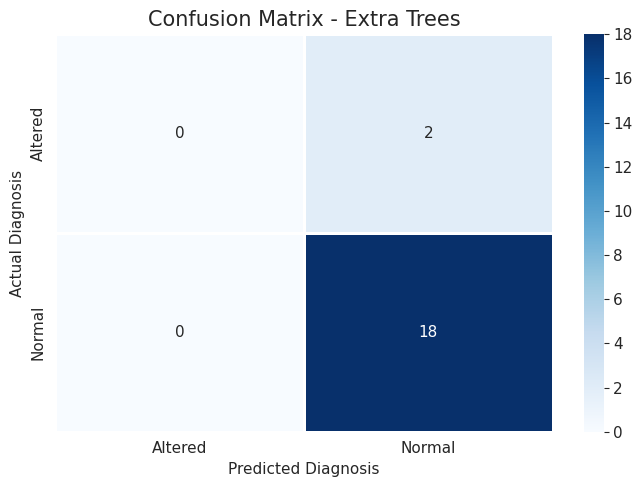

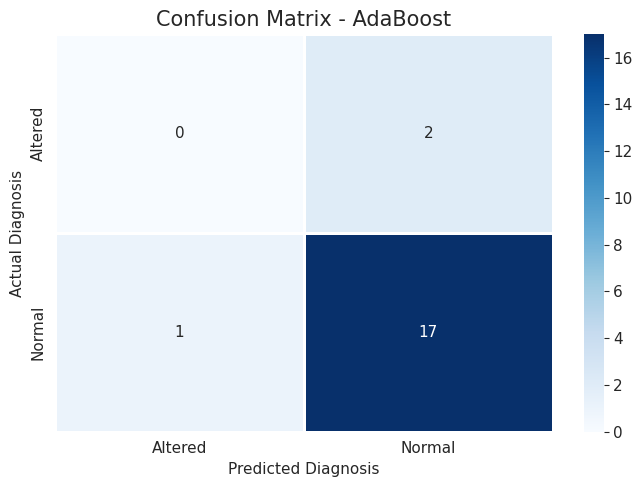

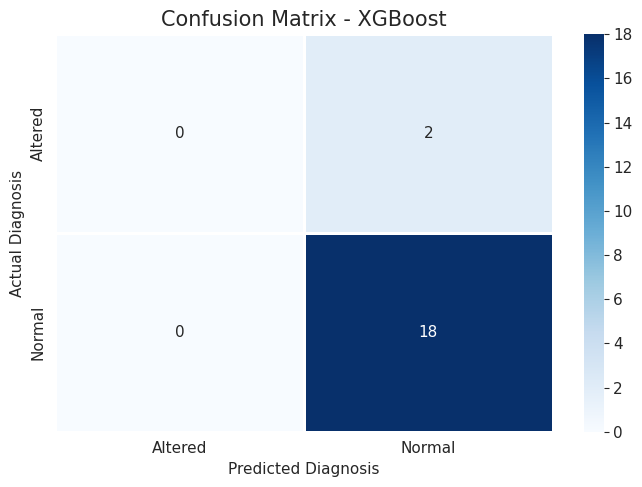

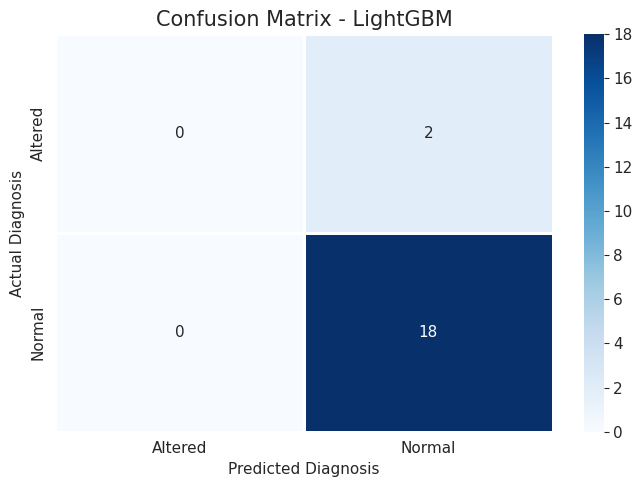

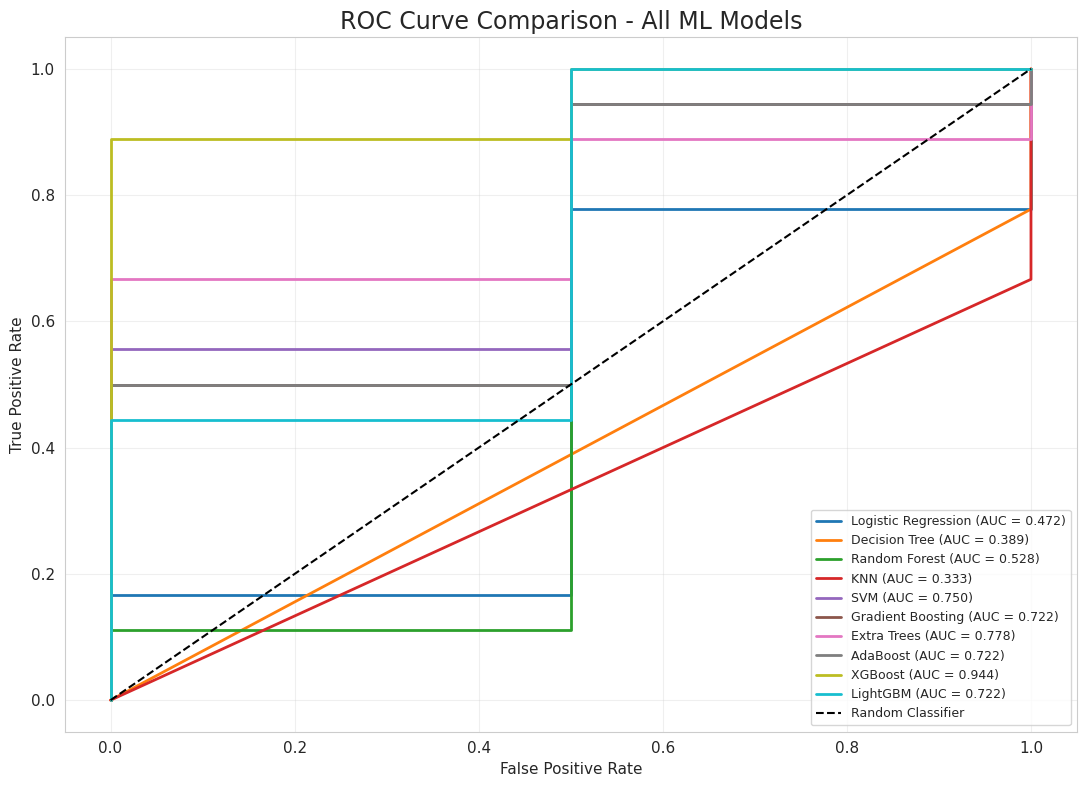

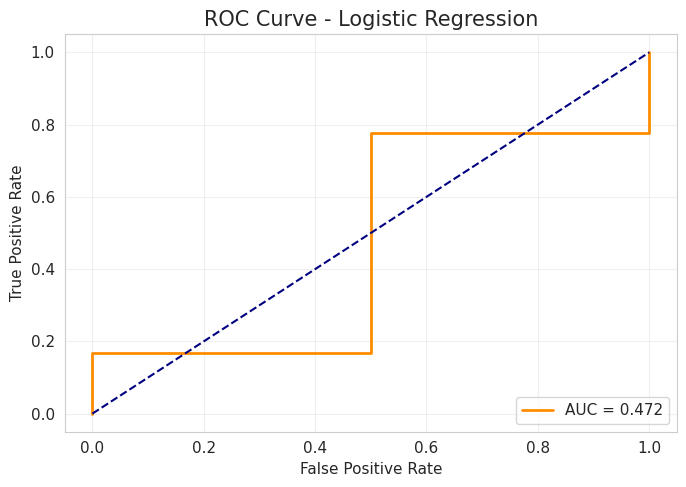

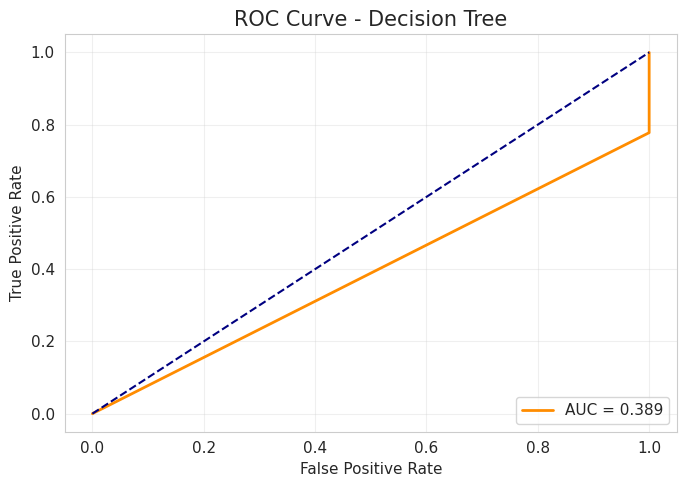

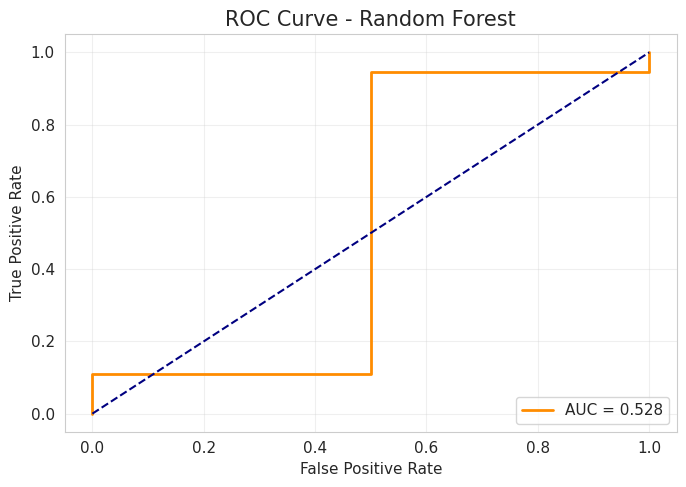

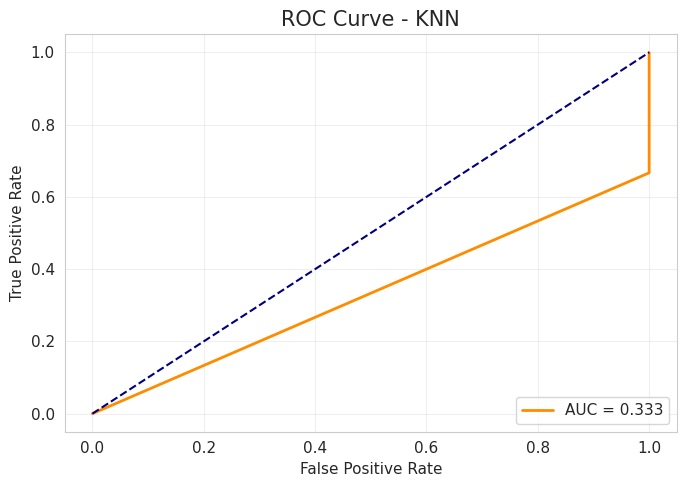

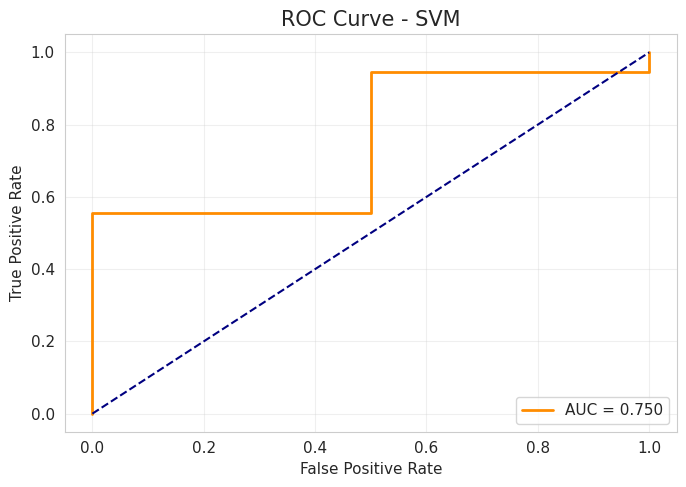

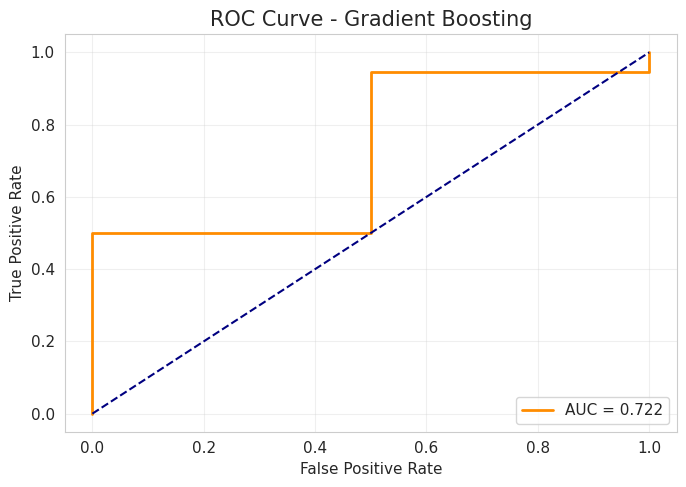

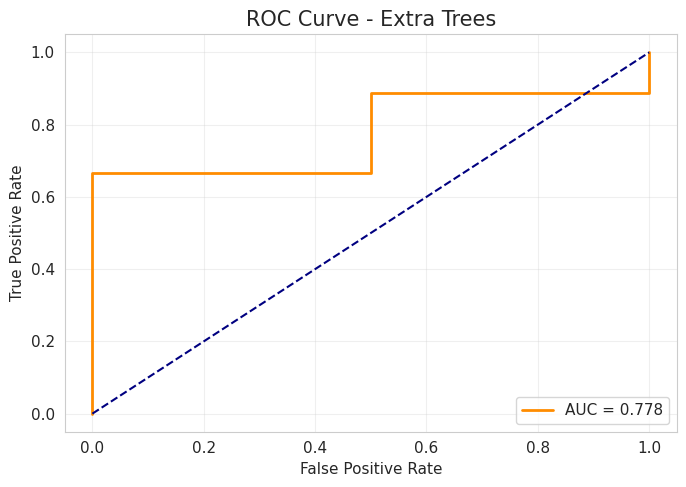

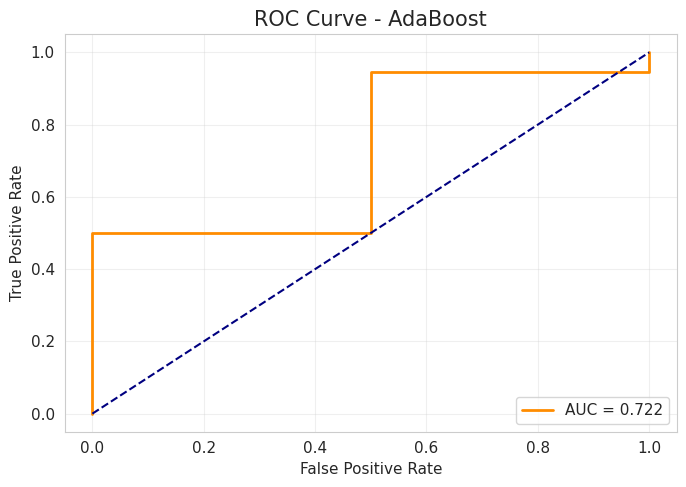

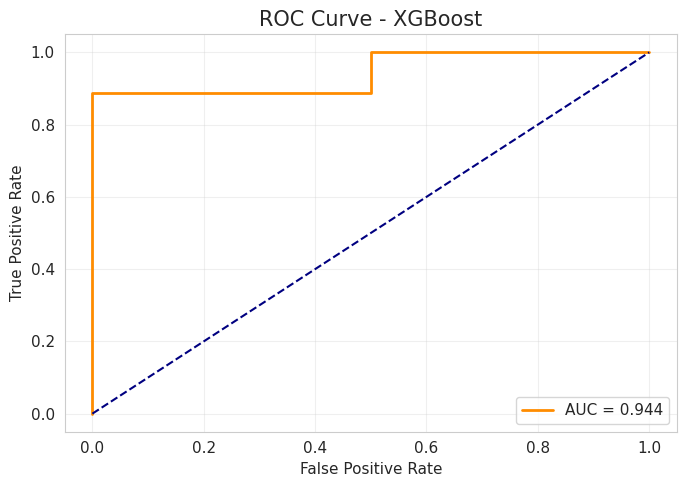

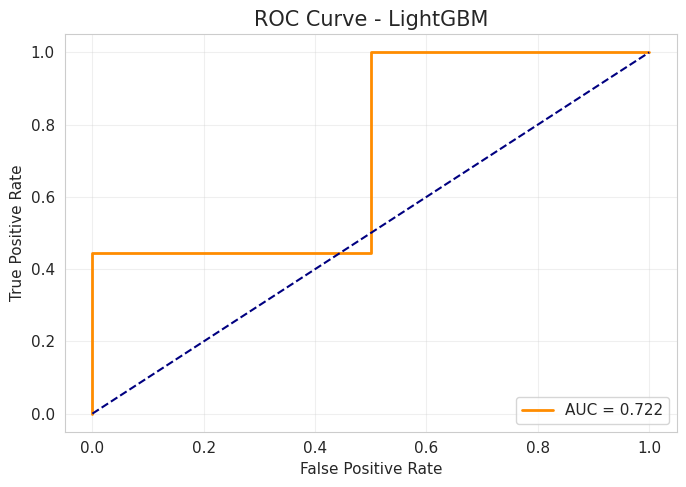


BEST MODEL RESULTS
Best Model: Decision Tree
Accuracy: 90.0 %
Precision: 81.0 %
Recall: 90.0 %
F1 Score: 85.26 %
ROC AUC: 0.3889

Feature Importance:


,Feature,Importance
6,Frequency of alcohol consumption,0.242264
3,Accident or serious trauma,0.209962
5,High fevers in the last year,0.151415
1,Age,0.147297
4,Surgical intervention,0.131464
8,Number of hours spent sitting per day,0.117598
0,Season,0.000000
2,Childish diseases,0.000000
7,Smoking habit,0.000000


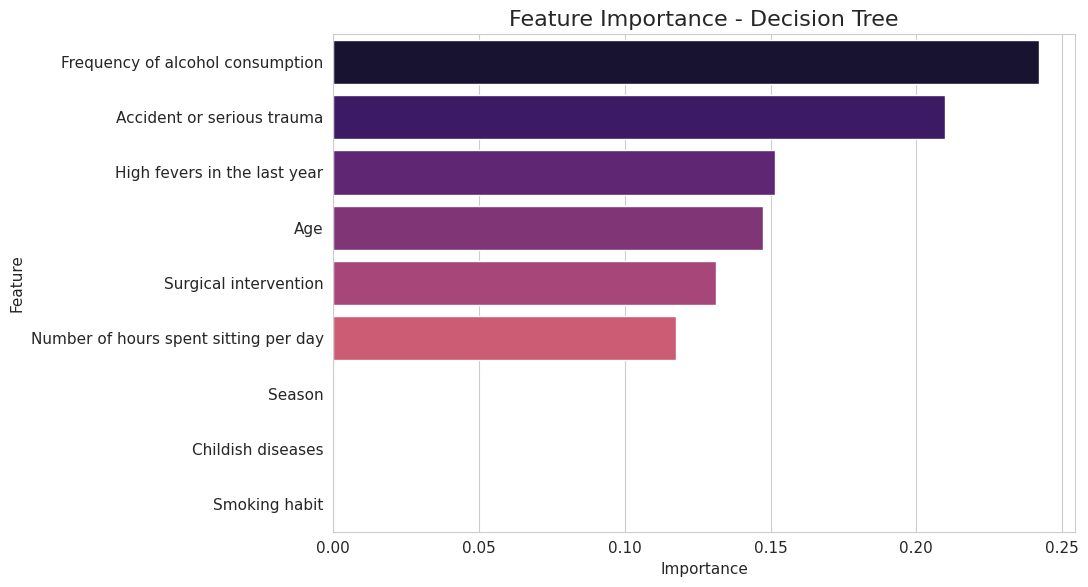


MACHINE LEARNING PIPELINE COMPLETED
Total Records: 99
Total Features: 9
Training Records: 79
Testing Records: 20
Models Successfully Trained: 10
Best Performing Model: Decision Tree

Final Model Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Decision Tree,90.0,81.000,90.0,85.263,0.389
1,Random Forest,90.0,81.000,90.0,85.263,0.528
2,Extra Trees,90.0,81.000,90.0,85.263,0.778
3,KNN,90.0,81.000,90.0,85.263,0.333
4,SVM,90.0,81.000,90.0,85.263,0.750
5,Gradient Boosting,90.0,81.000,90.0,85.263,0.722
6,LightGBM,90.0,81.000,90.0,85.263,0.722
7,XGBoost,90.0,81.000,90.0,85.263,0.944
8,Logistic Regression,85.0,80.526,85.0,82.703,0.472
9,AdaBoost,85.0,80.526,85.0,82.703,0.722



ALL MACHINE LEARNING MODELS COMPLETED SUCCESSFULLY!


In [14]:

# ==============================================================
# FERTILITY DATASET - COMPLETE MACHINE LEARNING CLASSIFICATION
# TRAIN TEST SPLIT + LABEL ENCODING + ML MODELS + ROC CURVES
# ==============================================================

# 1. IMPORT LIBRARIES
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

sns.set_style("whitegrid")

# ==============================================================
# 2. LOAD AND INSPECT DATA
# ==============================================================

# If df is already loaded, use it directly.
# Otherwise uncomment:
# df = pd.read_csv('/kaggle/input/your-dataset/file.csv')

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df['Diagnosis'].value_counts())

# ==============================================================
# 3. DATA CLEANING
# ==============================================================

df = df.copy()

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Remove rows where target is missing
df.dropna(subset=['Diagnosis'], inplace=True)

# Separate features and target
X = df.drop(columns=['Diagnosis'])
y = df['Diagnosis'].astype(str)

# Identify categorical columns
# These features are categorical even if stored as numbers.
known_categorical = [
    'Childish diseases',
    'Accident or serious trauma',
    'Surgical intervention',
    'High fevers in the last year',
    'Frequency of alcohol consumption',
    'Smoking habit'
]

categorical_cols = [
    col for col in X.columns
    if col in known_categorical
    or X[col].dtype == 'object'
    or isinstance(X[col].dtype, pd.CategoricalDtype)
    or X[col].dtype == 'bool'
]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("\nCategorical Features:")
print(categorical_cols)

print("\nNumerical Features:")
print(numerical_cols)

# ==============================================================
# 4. TRAIN TEST SPLITTING BEFORE ENCODING
# ==============================================================

# Stratified split maintains class proportions.
class_counts = y.value_counts()

stratify_target = y if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)

print("\nTRAIN TEST SPLIT")
print("=" * 50)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# ==============================================================
# 5. HANDLE MISSING VALUES
# ==============================================================

X_train = X_train.copy()
X_test = X_test.copy()

# Numerical missing values
if numerical_cols:
    num_imputer = SimpleImputer(strategy='median')

    X_train[numerical_cols] = num_imputer.fit_transform(
        X_train[numerical_cols]
    )

    X_test[numerical_cols] = num_imputer.transform(
        X_test[numerical_cols]
    )

# Categorical missing values
if categorical_cols:
    cat_imputer = SimpleImputer(strategy='most_frequent')

    X_train[categorical_cols] = cat_imputer.fit_transform(
        X_train[categorical_cols]
    )

    X_test[categorical_cols] = cat_imputer.transform(
        X_test[categorical_cols]
    )

# ==============================================================
# 6. LABEL ENCODING
# ==============================================================

# Encode categorical features using training data only.
label_encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    X_train[col] = le.fit_transform(
        X_train[col].astype(str)
    )

    # Unseen test categories are assigned -1.
    test_values = X_test[col].astype(str)

    mapping = {
        value: index
        for index, value in enumerate(le.classes_)
    }

    X_test[col] = test_values.map(mapping).fillna(-1).astype(int)

    label_encoders[col] = le

# Encode target variable
target_encoder = LabelEncoder()

y_train_encoded = target_encoder.fit_transform(y_train)

# Ensure the test labels belong to the training classes.
y_test_encoded = target_encoder.transform(y_test)

class_names = target_encoder.classes_

print("\nTarget Classes:")
print(class_names)

print("\nEncoded Training Target:")
print(np.unique(y_train_encoded))

print("\nLabel Encoding Completed!")

# ==============================================================
# 7. FEATURE SCALING
# ==============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed!")

# ==============================================================
# 8. DEFINE MACHINE LEARNING MODELS
# ==============================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=4,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=6,
        min_samples_split=3,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}

# Optional XGBoost
try:
    from xgboost import XGBClassifier

    models['XGBoost'] = XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        random_state=42,
        eval_metric='logloss'
    )

    print("XGBoost Added!")

except ImportError:
    print("XGBoost not installed. Skipping.")

# Optional LightGBM
try:
    from lightgbm import LGBMClassifier

    models['LightGBM'] = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        verbosity=-1
    )

    print("LightGBM Added!")

except ImportError:
    print("LightGBM not installed. Skipping.")

# ==============================================================
# 9. TRAIN MODELS AND EVALUATE PERFORMANCE
# ==============================================================

results = []
trained_models = {}
roc_probabilities = {}

for name, model in models.items():

    print("\n" + "=" * 70)
    print("TRAINING:", name)
    print("=" * 70)

    try:

        # Train
        model.fit(X_train_scaled, y_train_encoded)

        # Prediction
        y_pred = model.predict(X_test_scaled)

        # Prediction probabilities for ROC
        y_prob = model.predict_proba(X_test_scaled)

        # Evaluation metrics
        accuracy = accuracy_score(y_test_encoded, y_pred)

        precision = precision_score(
            y_test_encoded,
            y_pred,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test_encoded,
            y_pred,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test_encoded,
            y_pred,
            average='weighted',
            zero_division=0
        )

        # ROC AUC
        if len(class_names) == 2:
            auc_score = roc_auc_score(
                y_test_encoded,
                y_prob[:, 1]
            )
        else:
            auc_score = roc_auc_score(
                y_test_encoded,
                y_prob,
                multi_class='ovr',
                average='weighted',
                labels=np.arange(len(class_names))
            )

        # Store metrics
        results.append({
            'Model': name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100,
            'ROC AUC': auc_score
        })

        trained_models[name] = model
        roc_probabilities[name] = y_prob

        print("Accuracy :", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall   :", round(recall * 100, 2), "%")
        print("F1 Score :", round(f1 * 100, 2), "%")
        print("ROC AUC  :", round(auc_score, 4))

        print("\nClassification Report:")
        print(
            classification_report(
                y_test_encoded,
                y_pred,
                labels=np.arange(len(class_names)),
                target_names=class_names,
                zero_division=0
            )
        )

    except Exception as e:
        print("Model failed:", str(e))

# ==============================================================
# 10. MODEL PERFORMANCE COMPARISON
# ==============================================================

results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError("No model was successfully trained.")

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(results_df.round(3))

# ==============================================================
# 11. ACCURACY COMPARISON
# ==============================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Machine Learning Model Accuracy Comparison",
          fontsize=16)

plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=40, ha='right')

for i, value in enumerate(results_df['Accuracy']):
    plt.text(i, value + 0.5, f'{value:.2f}%',
             ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# ==============================================================
# 12. ALL METRICS COMPARISON
# ==============================================================

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

metrics_data = results_df.set_index('Model')[metrics]

metrics_data.plot(
    kind='bar',
    figsize=(15, 7),
    colormap='Set2',
    width=0.8
)

plt.title("All ML Models - Performance Metrics",
          fontsize=17)

plt.xlabel("Models")
plt.ylabel("Performance (%)")
plt.xticks(rotation=40, ha='right')
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

# ==============================================================
# 13. CONFUSION MATRICES FOR ALL MODELS
# ==============================================================

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test_encoded,
        y_pred,
        labels=np.arange(len(class_names))
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        linewidths=1,
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {name}", fontsize=15)
    plt.xlabel("Predicted Diagnosis")
    plt.ylabel("Actual Diagnosis")

    plt.tight_layout()
    plt.show()

# ==============================================================
# 14. ROC CURVE - ALL MODELS
# ==============================================================

plt.figure(figsize=(11, 8))

if len(class_names) == 2:

    for name, y_prob in roc_probabilities.items():

        fpr, tpr, thresholds = roc_curve(
            y_test_encoded,
            y_prob[:, 1]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f'{name} (AUC = {roc_auc:.3f})'
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='black',
        label='Random Classifier'
    )

    plt.title("ROC Curve Comparison - All ML Models",
              fontsize=17)

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.legend(loc='lower right', fontsize=9)

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:

    # Multiclass ROC: One-vs-Rest macro ROC curve
    y_test_binary = label_binarize(
        y_test_encoded,
        classes=np.arange(len(class_names))
    )

    for name, y_prob in roc_probabilities.items():

        all_fpr = np.unique(
            np.concatenate([
                roc_curve(y_test_binary[:, i], y_prob[:, i])[0]
                for i in range(len(class_names))
            ])
        )

        mean_tpr = np.zeros_like(all_fpr)

        for i in range(len(class_names)):

            fpr, tpr, _ = roc_curve(
                y_test_binary[:, i],
                y_prob[:, i]
            )

            mean_tpr += np.interp(all_fpr, fpr, tpr)

        mean_tpr /= len(class_names)

        macro_auc = auc(all_fpr, mean_tpr)

        plt.plot(
            all_fpr,
            mean_tpr,
            linewidth=2,
            label=f'{name} (Macro AUC = {macro_auc:.3f})'
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle='--',
        color='black',
        label='Random Classifier'
    )

    plt.title("Multiclass ROC Curve - All Models",
              fontsize=17)

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc='lower right', fontsize=9)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ==============================================================
# 15. INDIVIDUAL ROC CURVES
# ==============================================================

if len(class_names) == 2:

    for name, y_prob in roc_probabilities.items():

        fpr, tpr, thresholds = roc_curve(
            y_test_encoded,
            y_prob[:, 1]
        )

        roc_auc = auc(fpr, tpr)

        plt.figure(figsize=(7, 5))

        plt.plot(
            fpr,
            tpr,
            color='darkorange',
            linewidth=2,
            label=f'AUC = {roc_auc:.3f}'
        )

        plt.plot(
            [0, 1], [0, 1],
            linestyle='--',
            color='navy'
        )

        plt.title(f"ROC Curve - {name}", fontsize=15)
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend(loc='lower right')
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

# ==============================================================
# 16. BEST MODEL
# ==============================================================

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print("\n" + "=" * 70)
print("BEST MODEL RESULTS")
print("=" * 70)

print("Best Model:", best_model_name)
print("Accuracy:",
      round(results_df.iloc[0]['Accuracy'], 2), "%")
print("Precision:",
      round(results_df.iloc[0]['Precision'], 2), "%")
print("Recall:",
      round(results_df.iloc[0]['Recall'], 2), "%")
print("F1 Score:",
      round(results_df.iloc[0]['F1 Score'], 2), "%")
print("ROC AUC:",
      round(results_df.iloc[0]['ROC AUC'], 4))

# ==============================================================
# 17. FEATURE IMPORTANCE (TREE-BASED BEST MODEL)
# ==============================================================

if hasattr(best_model, 'feature_importances_'):

    importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': best_model.feature_importances_
    }).sort_values(
        by='Importance',
        ascending=False
    )

    print("\nFeature Importance:")
    display(importance)

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=importance,
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='magma',
        legend=False
    )

    plt.title(
        f"Feature Importance - {best_model_name}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

elif best_model_name == 'Logistic Regression':

    coefficients = np.mean(
        np.abs(best_model.coef_),
        axis=0
    )

    importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': coefficients
    }).sort_values(
        by='Importance',
        ascending=False
    )

    print("\nAbsolute Logistic Regression Coefficients:")
    display(importance)

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=importance,
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='viridis',
        legend=False
    )

    plt.title("Logistic Regression Feature Importance")
    plt.tight_layout()
    plt.show()

# ==============================================================
# 18. FINAL SUMMARY
# ==============================================================

print("\n" + "=" * 70)
print("MACHINE LEARNING PIPELINE COMPLETED")
print("=" * 70)

print("Total Records:", len(df))
print("Total Features:", X.shape[1])
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Models Successfully Trained:", len(trained_models))
print("Best Performing Model:", best_model_name)

print("\nFinal Model Results:")
display(results_df.round(3))

print("\nALL MACHINE LEARNING MODELS COMPLETED SUCCESSFULLY!")


## Thank you..pls upvote!!!!!!!!